# Chapter 6: Quantum Fourier Transform and Phase Estimation

*This chapter focuses on two fundamental quantum algorithms for spectral analysis. We derive the Quantum Fourier Transform (QFT) circuit and discuss its resource scaling. Building on the QFT, we introduce the Quantum Phase Estimation (QPE) algorithm, which extracts eigenvalues of unitary operators (e.g. energy eigenvalues via time evolution). Variants of QPE (iterative, Bayesian) are covered, along with discussions of precision and error, of the choice of the evolution time, and of the Trotter error inside the controlled evolution. The algorithm is applied to the ground-state energies of the model Hamiltonians of the previous chapters, and the roles of the trial state and of the overlap with the target eigenstate are examined. As an application of phase estimation beyond energies we present the Harrow--Hassidim--Lloyd algorithm for linear systems of equations, with examples from a discretized differential equation and from the resolvent of a many-body Hamiltonian, and discuss its assumptions.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

Every method of Chapter 3 was classical, and several of
them ran into the exponential wall of Section *The exponential wall*: the number
of Slater determinants that can be built from $M$ single-particle states
grows as $\binom{M}{N}$, and no amount of cleverness in the algorithm
changes that. Chapter 4 moved the wall rather than
removing it, by storing a state of $M$ modes in $M$ qubits instead of in
$2^M$ complex numbers, and it left every model of the book as a Pauli sum
$\hat{H}=\sum_\alpha h_\alpha P_\alpha$ together with the circuits that
exponentiate it term by term. The question is then what can actually be
computed with such a register, and this chapter answers it for the one
quantity we have wanted throughout: an eigenvalue of a Hamiltonian.

The algorithm is *quantum phase estimation*. Its input is a unitary
and one of its eigenstates; its output is the eigenphase, written out in
binary in a register of qubits, to a precision that improves
*exponentially* with the size of that register. Its engine is the
*quantum Fourier transform*, which is the subject of the first part
of the chapter and which is worth the space: the QFT is the transformation
that converts phase information into computational-basis information, and
essentially every quantum algorithm with an exponential speed-up uses
it. Nothing new is needed from the formalism. Chapter 2
set out the gate model, with states $\vert x_1x_2\cdots x_n\rangle$ in
the computational basis, unitaries acting on one or two qubits at a time
and measurements given by projections, and observed that quantum
computing is a restricted form of linear algebra: matrix-vector
multiplications with special unitary matrices on exponentially large
vectors. This chapter is that observation carried through to an
algorithm.

The chapter runs in four parts. The first,
Sections *From the discrete Fourier transform to the quantum one*--*Cost, approximation and conventions*, is the quantum Fourier
transform: the definition, the product form derived twice, the circuit,
the gate count, the approximate transform and the bit-ordering convention
that causes more confusion than any other detail of the subject. The
second, Sections *Quantum phase estimation* and *From phases to energies*, is phase
estimation: the algorithm, why the inverse QFT is the right final step,
the exact and the inexact case, the precision, the one-control-qubit
variants, and the bridge from the eigenphases of $e^{-i\hat{H}t}$ to
energies. The third, Sections *Two small Hamiltonians, worked through* and *The model Hamiltonians on a quantum computer*,
runs the algorithm on the Hamiltonians of Chapter 4, from
the one-qubit pairing Hamiltonian of Eq. (4.18) to the
eight-qubit Hubbard ring, and confronts the two errors that a real
calculation must balance, the finite register and the Trotterization of
the evolution operator, as well as the question of what happens when the
input is not an eigenstate. The fourth, Section *An application: the linear-system algorithm of Harrow, Hassidim and Lloyd*, is an
application of phase estimation to something other than an energy: the
algorithm of Harrow, Hassidim and Lloyd for linear systems of equations,
which uses the phase register to invert a matrix spectrally, and which we
apply to a discretized differential equation and to the resolvent
$(z-\hat{H})^{-1}$ of a many-body Hamiltonian, the object behind every
Green's function. The programs are in `BookPrograms/chapter6/`:
a QFT built gate by gate on the simulator of Chapter 2
and checked against the Fourier matrix, a `PhaseEstimation` class,
the model calculations, and an `HHL` class. Every number quoted
below comes from them.


## From the discrete Fourier transform to the quantum one

The classical discrete Fourier transform of a vector
$x=(x_0,\dots,x_{N-1})$ is

$$
y_k = \frac{1}{\sqrt{N}}\sum_{j=0}^{N-1}x_j\,e^{2\pi i jk/N},
  \qquad k=0,\dots,N-1 ,\tag{6.1}
$$

that is, multiplication by the unitary matrix

\begin{equation*}
\matr{F}_N = \frac{1}{\sqrt{N}}
  \begin{pmatrix}
    1 & 1 & 1 & \cdots & 1\\
    1 & \omega & \omega^2 & \cdots & \omega^{N-1}\\
    1 & \omega^2 & \omega^4 & \cdots & \omega^{2(N-1)}\\
    \vdots & \vdots & \vdots & \ddots & \vdots\\
    1 & \omega^{N-1} & \omega^{2(N-1)} & \cdots & \omega^{(N-1)^2}
  \end{pmatrix},
  \qquad \omega = e^{2\pi i/N} .\tag{6.2}
\end{equation*}

The matrix is unitary, $\matr{F}_N^{\dagger}\matr{F}_N=\matr{I}$, by the
orthogonality relation $\sum_{j}\omega^{j(k-k')}=N\delta_{kk'}$; it
therefore preserves inner products and norms, which is exactly the
condition for a matrix to be an admissible quantum gate. Its columns are
an orthonormal basis, and $\matr{F}_N$ is the change of basis between
them and the computational basis.

The *quantum* Fourier transform is the same matrix, applied to the
amplitudes of a quantum state. For $N=2^{n}$ it is the unitary defined on
the computational basis $\vert x\rangle$ of $n$ qubits by

$$
\mathrm{QFT}_N\vert x\rangle = \frac{1}{\sqrt{N}}
    \sum_{k=0}^{N-1}e^{2\pi i xk/N}\vert k\rangle,
  \qquad x=0,\dots,N-1 ,\tag{6.3}
$$

and extended to a general state $\vert\psi\rangle=\sum_x c_x\vert x\rangle$ by
linearity, $\mathrm{QFT}_N\vert\psi\rangle=\sum_x c_x\,\mathrm{QFT}_N\vert x\rangle$.
Here and throughout the chapter the integer $x$ and the bit string
$x_1x_2\cdots x_n$ of the register are the same object, with qubit $0$ of
Chapters 2--4 holding the most
significant bit $x_1$,

$$
x = \sum_{j=1}^{n}x_j 2^{n-j},
  \qquad x_j\in\{0,1\} .\tag{6.4}
$$

Two things should be said at once, because they are the source of both
the power and the disappointment of the QFT. The power: the transform
acts on $N=2^{n}$ amplitudes using, as we shall see, only $\bigO(n^2)$
gates, against the $\bigO(N\log N)$ operations of the classical fast
Fourier transform, exponentially fewer. The disappointment: the result
sits in the *amplitudes* of a quantum state, which cannot be read
out. Measuring gives one basis state drawn from $\vert y_k\vert^2$, not the
vector $y$. The QFT is therefore useless as a subroutine for computing
Fourier transforms of data, and enormously useful as a subroutine inside
algorithms that need only one number out of the transform, a period, or,
as here, a phase.

### The product form

Everything about the QFT circuit follows from rewriting
Eq. (6.3) as a product of one-qubit states. We do it twice: once
in general, and once explicitly for two qubits, where every step can be
followed by eye. Besides the binary expansion (6.4) we need
the *binary fraction*

$$
0.x_jx_{j+1}\dots x_n = \frac{x_j}{2}+\frac{x_{j+1}}{2^2}
    + \dots + \frac{x_n}{2^{n-j+1}} .\tag{6.5}
$$

This notation is not a convenience: the phases of the QFT factor into
exactly such fractions, and the same fractions reappear as the output of
phase estimation in Section *Quantum phase estimation*.

*The general derivation.* Start from Eq. (6.3) with $N=2^n$ and write the *output*
label in binary, $k=\sum_{m=1}^{n}k_m2^{n-m}$. Then

$$
\frac{xk}{2^n} = x\sum_{m=1}^{n}\frac{k_m}{2^{m}},
  \qquad\text{so}\qquad
  e^{2\pi i xk/2^n} = \prod_{m=1}^{n}e^{2\pi i x k_m/2^{m}} .\tag{6.6}
$$

The exponential has factorized into one term per output qubit, and each
term depends on $k$ only through the single bit $k_m$. A sum over all $k$
is a sum over all the bits independently, so it factorizes too:

$$
\mathrm{QFT}_N\vert x\rangle = \frac{1}{2^{n/2}}
    \bigotimes_{m=1}^{n}\left(\vert 0\rangle+e^{2\pi i x/2^{m}}\vert 1\rangle\right) .\tag{6.7}
$$

Finally, $e^{2\pi i x/2^m}$ depends only on the fractional part of $x/2^m$,
and that fractional part is precisely the binary fraction
$0.x_{n-m+1}x_{n-m+2}\dots x_n$. Hence

\begin{equation*}
\begin{aligned}
  \mathrm{QFT}_N\vert x_1x_2\dots x_n\rangle = \frac{1}{2^{n/2}}
    &\left(\vert 0\rangle+e^{2\pi i\,0.x_n}\vert 1\rangle\right)
    \otimes\left(\vert 0\rangle+e^{2\pi i\,0.x_{n-1}x_n}\vert 1\rangle\right)\\
    &\otimes\cdots\otimes
    \left(\vert 0\rangle+e^{2\pi i\,0.x_1x_2\dots x_n}\vert 1\rangle\right) .
  \end{aligned}\tag{6.8}
\end{equation*}

Three consequences, all of them important. First, the output is a
*product* state: the QFT of a computational basis state is
completely unentangled, and each qubit carries a phase and nothing else.
It is worth pausing on that, because the $\bigotimes$ in
Eq. (6.8) is doing real work. A general state of $n$ qubits
needs $2^n$ amplitudes; a product state needs $2n$. The QFT of a basis
state is therefore an exponentially compressible object, and that is
precisely why it can be built with polynomially many gates. Second, the
first output qubit depends only on the *last* input bit, the second
on the last two, and so on: the output order is reversed relative to the
input. Third, each factor can be produced by a Hadamard followed by a few
controlled phase rotations, which is the circuit.

*Two qubits, explicitly.* For $n=2$, write $\vert x\rangle=\vert x_1x_2\rangle$ with $x=2x_1+x_2$, and
$k=2k_1+k_2$. Then

$$
\mathrm{QFT}_4\vert x_1x_2\rangle = \frac{1}{2}
    \sum_{k_1,k_2\in\{0,1\}}
    e^{2\pi i(2x_1+x_2)(2k_1+k_2)/4}\vert k_1k_2\rangle ,\tag{6.9}
$$

and the exponent expands as

$$
\frac{(2x_1+x_2)(2k_1+k_2)}{4}
   = x_1k_1 + \frac{x_1k_2}{2} + \frac{x_2k_1}{2} + \frac{x_2k_2}{4} .\tag{6.10}
$$

The first term is an *integer*, so $e^{2\pi i x_1k_1}=1$ and it drops
out. This is the essential simplification, and it is what makes the QFT
efficient: the high-order products of input and output bits contribute
nothing at all. Collecting what remains by output bit,

$$
e^{2\pi i xk/4} = e^{2\pi i k_1\left(\frac{x_2}{2}\right)}\,
    e^{2\pi i k_2\left(\frac{x_1}{2}+\frac{x_2}{4}\right)}
   = e^{2\pi i k_1(0.x_2)}\,e^{2\pi i k_2(0.x_1x_2)} ,\tag{6.11}
$$

so the sum factorizes into

$$
\mathrm{QFT}_4\vert x_1x_2\rangle =
    \frac{1}{\sqrt2}\left(\vert 0\rangle+e^{2\pi i\,0.x_2}\vert 1\rangle\right)
    \otimes
    \frac{1}{\sqrt2}\left(\vert 0\rangle+e^{2\pi i\,0.x_1x_2}\vert 1\rangle\right) ,\tag{6.12}
$$

which is Eq. (6.8) for $n=2$. The first factor depends only
on $x_2$ and the second on both bits: the least significant phase appears
first, which is the reversal again, now visible in three lines of algebra.

### The circuit

Two gates suffice, and both are in Chapter 2. The
Hadamard $\mathrm{H}=(X+Z)/\sqrt2$ creates an equal superposition, and
the phase rotation

\begin{equation*}
R_k = \begin{pmatrix}1 & 0\\ 0 & e^{2\pi i/2^{k}}\end{pmatrix}\tag{6.13}
\end{equation*}

adds one binary digit to the phase. $R_k$ is a rotation about the $z$
axis up to a global phase, $R_k = e^{i\pi/2^{k}}R_z(2\pi/2^{k})$, and
$R_1=Z$, $R_2=S$, $R_3=T$ are the standard names. A *controlled*
$R_k$ applies the rotation only on the subspace where the control qubit is
$\vert 1\rangle$; it is symmetric in its two qubits, since it multiplies
the single amplitude of $\vert 11\rangle$ by $e^{2\pi i/2^k}$ and leaves
the other three alone.

Read Eq. (6.8) backwards to see the construction. The last
output factor carries the phase $e^{2\pi i\,0.x_1x_2\dots x_n}$. A Hadamard
on qubit $1$ produces $\vert 0\rangle+e^{2\pi i\,0.x_1}\vert 1\rangle$,
since $\mathrm{H}\vert x_1\rangle=(\vert 0\rangle+(-1)^{x_1}\vert 1\rangle)/\sqrt2$
and $(-1)^{x_1}=e^{2\pi i\,0.x_1}$, and controlled rotations from qubits
$2,3,\dots,n$ append the digits $x_2,x_3,\dots,x_n$ one at a time: a
controlled $R_2$ from qubit $2$ multiplies the $\vert 1\rangle$ component
by $e^{2\pi i x_2/4}$, a controlled $R_3$ from qubit $3$ by
$e^{2\pi i x_3/8}$, and so on. The same pattern then repeats on qubit $2$,
which needs the digits $x_3,\dots,x_n$, and so on down the register. At
the end the qubit that was processed first holds the *last* factor
of Eq. (6.8), so the register is reversed with
$\lfloor n/2\rfloor$ SWAP gates. Figures 6.1
and 6.2 show the result for two and three qubits, and for
$n=3$ the product form reads

$$
\mathrm{QFT}_8\vert x_1x_2x_3\rangle = \frac{1}{\sqrt8}
    \left(\vert 0\rangle+e^{2\pi i\,0.x_3}\vert 1\rangle\right)
    \otimes\left(\vert 0\rangle+e^{2\pi i\,0.x_2x_3}\vert 1\rangle\right)
    \otimes\left(\vert 0\rangle+e^{2\pi i\,0.x_1x_2x_3}\vert 1\rangle\right),\tag{6.14}
$$

so the first qubit needs the phase contributions $x_2/2+x_3/4$, which is
exactly what the controlled $R_2$ and $R_3$ of Fig. 6.2
supply.

![The two-qubit QFT a Hadamard on qubit , a controlled  with , a Hadamar](../../BookFigures/chapter6/6-qft2.png)

*Figure 6.1: The two-qubit QFT: a Hadamard on qubit $1$, a controlled $R_2$ with $R_2=\mathrm{diag}(1,e^{i\pi/2})$, a Hadamard on qubit $2$, and a SWAP that undoes the reversal of Eq. (6.12).*

![The three-qubit QFT. Hadamard on , then controlled  and  from  and  Ha](../../BookFigures/chapter6/6-qft3.png)

*Figure 6.2: The three-qubit QFT. Hadamard on $x_1$, then controlled $R_2$ and $R_3$ from $x_2$ and $x_3$; Hadamard on $x_2$, then a controlled $R_2$ from $x_3$; Hadamard on $x_3$; then the reversal, which for three qubits is a single SWAP of the outer pair. The nested triangular structure is the general pattern.*

The general $n$-qubit circuit is therefore: for $j=1,\dots,n$, apply a
Hadamard to qubit $j$ and then, for each later qubit $k>j$, a controlled
$R_{k-j+1}$ with control $k$ and target $j$; finally reverse the
register. The function `qft_circuit` in `qft.py` builds it
as a `Circuit` of Chapter 2, in the same
dozen lines,


In [2]:
from qft import qft_circuit, qft_matrix
from statevector import StateVector
import numpy as np

circ = qft_circuit(3)                       # H, controlled R_k, SWAP, Fig. 6.3
print(circ.draw())
print(np.abs(circ.unitary() - qft_matrix(3)).max())      # the Fourier matrix, to 1e-15
out = circ.run(StateVector.from_bits("101"))
print(np.round(out.psi, 4))                 # the eight amplitudes of QFT_8 |101>


q0: |0>--[H]-[R2]-[R3]---------------x---
q1: |0>-------*----|---[H]-[R2]------|---
q2: |0>------------*--------*---[H]--x---
1.415262216750919e-15
[ 0.3536+0.j     -0.25  -0.25j    0.    +0.3536j  0.25  -0.25j
 -0.3536+0.j      0.25  +0.25j   -0.    -0.3536j -0.25  +0.25j  ]


and the script checks, for $n$ up to five, that the unitary of the circuit
is the matrix of Eq. (6.2), that its action on every
basis state is the product state of Eq. (6.8) built with no
circuit at all, that its action on a random state is
`numpy.fft.ifft` with orthonormal scaling, and that the inverse
circuit undoes it, all to $3.5\times10^{-15}$. The second check is the one
that matters, since the product form is built directly from the
binary-fraction factorization and therefore tests the derivation rather
than the implementation's self-consistency.

### A worked example

Take $\vert x\rangle=\vert 101\rangle$, so $x_1=1$, $x_2=0$, $x_3=1$ and
$x=5$. The product form gives

$$
\mathrm{QFT}_8\vert 101\rangle = \frac{1}{\sqrt8}
    \left(\vert 0\rangle+e^{2\pi i\,0.1}\vert 1\rangle\right)
    \otimes\left(\vert 0\rangle+e^{2\pi i\,0.01}\vert 1\rangle\right)
    \otimes\left(\vert 0\rangle+e^{2\pi i\,0.101}\vert 1\rangle\right) .\tag{6.15}
$$

Evaluating the binary fractions, $0.1=\tfrac12$, $0.01=\tfrac14$ and
$0.101=\tfrac12+\tfrac18=\tfrac58$, so
$e^{2\pi i\,0.1}=-1$, $e^{2\pi i\,0.01}=i$, $e^{2\pi i\,0.101}=e^{5\pi i/4}$, and

$$
\mathrm{QFT}_8\vert 101\rangle = \frac{1}{\sqrt8}
    \left(\vert 0\rangle-\vert 1\rangle\right)\otimes\left(\vert 0\rangle+i\vert 1\rangle\right)
    \otimes\left(\vert 0\rangle+e^{5\pi i/4}\vert 1\rangle\right) .\tag{6.16}
$$

Expanding the product gives eight amplitudes, all of modulus
$1/\sqrt8=0.353553$, with the phase of $\vert k\rangle$ equal to
$2\pi\times(5k/8 \bmod 1)$, which is Eq. (6.3) with $x=5$, as it
must be. `qft.py` prints the eight amplitudes and confirms both
statements, and Fig. 6.3 draws them.

![The eight amplitudes of mathrmQFT8vert 101rangle, drawn as vectors in ](../../BookFigures/chapter6/qft_phases.png)

*Figure 6.3: The eight amplitudes of $\mathrm{QFT}_8\vert 101\rangle$, drawn as vectors in the complex plane and labelled by the output basis state $\vert k\rangle$ they belong to. Every one of them has the same modulus $1/\sqrt8=0.3536$, marked by the dashed circle, and the phase of $\vert k\rangle$ is $2\pi\times(5k/8\bmod1)$. Since $5$ and $8$ have no common factor the eight vectors occupy the eight eighth-roots of unity exactly once each, reached in the order $0,5,2,7,4,1,6,3$ as $k$ runs from $0$ to $7$. Produced by `qft.py`.*

Two things in Fig. 6.3 are worth dwelling on, and both
are properties of the transform rather than of this particular input.
The first is that all eight vectors have the same length. A measurement
of the transformed register in the computational basis would return each
of the eight outcomes with probability $1/8$, that is, it would return
nothing at all: the entire content of $\mathrm{QFT}_8\vert 101\rangle$ sits
in the angles, and angles are exactly what a single measurement cannot
see. This is the disappointment of Section *From the discrete Fourier transform to the quantum one* made
visual, and it is why the QFT is never the last step of an algorithm. The
second is the arrangement of the angles. Reading the labels anticlockwise
from $\vert 000\rangle$ gives $0,5,2,7,4,1,6,3$, which is the sequence
$5k\bmod 8$: the input integer has been turned into a *rotation
rate*, one eighth of a turn per unit of $x$ per unit of $k$. Because $5$
is coprime to $8$ the rate is primitive and the eight vectors are all
distinct, whereas for $x=4$ the phase $4k/8$ takes only the two values $0$
and $\tfrac12$, and the eight vectors would pile up four deep on two
positions. That collapse is periodicity, and reading it off is precisely
what Shor's algorithm does; here we shall instead read off a single angle,
which is phase estimation. The product form can be traced directly in the
picture: expanding Eq. (6.16), the amplitude of
$\vert k_1k_2k_3\rangle$ is $(-1)^{k_1}\,i^{k_2}\,e^{5\pi ik_3/4}/\sqrt8$,
so the first output bit contributes a half-turn, the second a
quarter-turn and the third five-eighths of a turn, independently of one
another. Three angles, one per qubit, generate all eight, and that is the
reason the circuit needs three Hadamards and three controlled rotations
rather than an $8\times8$ matrix multiplication.

### Cost, approximation and conventions

*The inverse.* The inverse QFT is obtained by reversing the order of the gates and
replacing each $R_k$ by $R_k^{\dagger}$; the SWAP network is its own
inverse. It is therefore no more expensive than the forward transform, and
in practice it is the one algorithms use, phase estimation among them.

*The gate count.* Counting the circuit of Section *The circuit*: $n$ Hadamards,
$\sum_{j=1}^{n}(n-j)=n(n-1)/2$ controlled rotations, and $\lfloor
n/2\rfloor$ swaps, so

$$
\text{gates} = \bigO(n^2) .\tag{6.17}
$$

Compare the classical cost of applying $\matr{F}_N$ directly to a
$2^n$-dimensional vector, which is $\bigO(N^2)=\bigO(4^{n})$ operations, or
$\bigO(N\log N)$ with the fast Fourier transform; Table 6.1
gives the numbers.

| $n$ | $\mathrm{H}$ | controlled $R_k$ | swaps | direct classical DFT |
|---|---|---|---|---|
| $3$ | $3$ | $3$ | $1$ | $6.4\times10^{1}$ |
| $6$ | $6$ | $15$ | $3$ | $4.1\times10^{3}$ |
| $10$ | $10$ | $45$ | $5$ | $1.0\times10^{6}$ |
| $100$ | $100$ | $4950$ | $50$ | $1.6\times10^{60}$ |

*Table 6.1: The cost of the QFT circuit against the cost of multiplying by
the $2^n\times2^n$ Fourier matrix. At $n=100$ the quantum circuit needs
about five thousand gates and the classical matrix multiplication needs
more operations than there are atoms in the observable universe. Produced
by `qft.py`.*

*The approximate QFT.* The rotation $R_k$ turns the phase by $2\pi/2^{k}$, which for large $k$ is
tiny. Dropping every controlled rotation with $k-j+1>d$ gives the
*approximate* QFT, with $\bigO(nd)$ gates instead of $\bigO(n^2)$;
choosing $d\sim\log n$ keeps the error bounded and gives
$\bigO(n\log n)$. Table 6.2 and Fig. 6.4
show the trade on six qubits, and the shape they reveal is not the one
the asymptotic argument leads one to expect. Keeping the five largest
rotations, every controlled $R_2$, each of which turns the phase by a
quarter of a turn, lowers the largest amplitude error only from
$2.50\times10^{-1}$ to $2.43\times10^{-1}$, a gain of three per cent for a
third of the circuit. The error then falls by roughly a factor of three
at each further level, while the cost of a level shrinks: level $d$ adds
$n-d+1$ rotations, so the step from $d=5$ to $d=6$ is a single controlled
$R_6$, turning the phase by $2\pi/64\approx5.6^{\circ}$, and that one gate
takes the error from $1.23\times10^{-2}$ to zero. The marginal value of a
controlled rotation therefore *increases* along the ladder, which is
the opposite of the truncation's motivation. There is no contradiction,
only a question of scale. The bound of Exercise 6.2, $2\pi n2^{-d}$,
equals $37.7\times2^{-d}$ for $n=6$ and does not drop below unity until
$d=6$: over the whole of Fig. 6.4 the estimate is
vacuous, and what the figure shows is the pre-asymptotic regime in which
every rotation still matters. The prescription $d\sim\log_2 n$ becomes a
saving only when $n$ is large enough that $\log_2 n$ is genuinely smaller
than $n$; at $n=100$, the last row of Table 6.1, it
replaces the $4950$ controlled rotations by some seven hundred, and there
it earns its keep. The lesson for a small calculation is to keep the whole
triangle, and the lesson for a large one is that the gates one may safely
discard are the numerous cheap-looking ones at the far end of a
*long* ladder, not the last few of a short one.

| $d$ | controlled rotations | largest amplitude error |
|---|---|---|
| $1$ | $0$ | $2.50\times10^{-1}$ |
| $2$ | $5$ | $2.43\times10^{-1}$ |
| $3$ | $9$ | $1.29\times10^{-1}$ |
| $4$ | $12$ | $3.67\times10^{-2}$ |
| $5$ | $14$ | $1.23\times10^{-2}$ |
| $6$ | $15$ | $1.4\times10^{-16}$ (exact) |

*Table 6.2: The approximate QFT on $n=6$ qubits, applied to $\vert x\rangle$
with $x=37$: the number of controlled rotations kept when only $R_k$ with
$k\le d$ are retained, and the largest error in any output amplitude.
Produced by `qft.py`.*

![The largest amplitude error of the approximate mathrmQFT6 applied to v](../../BookFigures/chapter6/aqft_error.png)

*Figure 6.4: The largest amplitude error of the approximate $\mathrm{QFT}_6$ applied to $\vert x\rangle$ with $x=37$, against the number of controlled rotations retained, for the six truncation levels $d=1,\dots,6$ of Table 6.2; the exact transform is drawn on the $10^{-17}$ floor of the axis. The curve is nearly flat over its first third and then falls by about a factor of three per level, so that the last and cheapest rotations are the ones that carry the accuracy. Produced by `qft.py`.*

*Bit reversal: the commonest confusion.* Equation (6.8) produces the qubits in reversed order, and
the final SWAP network exists only to undo that. Many software libraries
omit the swaps and document the reversed convention instead, since a
relabelling costs nothing classically. The consequence is that a circuit
copied from one library into another can be silently wrong.
`qft.py` makes the statement precise: without the swaps the
amplitude that should sit on $\vert k\rangle$ sits on the basis state whose
bits are those of $k$ in reverse order, so that for $\mathrm{QFT}_8\vert 001\rangle$
the phase $1/8$ appears on $\vert 100\rangle$, $2/8$ on $\vert 010\rangle$
and $4/8$ on $\vert 001\rangle$. When in doubt, transform $\vert 0\cdots01\rangle$
and look at where the phase $e^{2\pi i/N}$ ends up.


## Quantum phase estimation

Let $U$ be unitary with an eigenstate $\vert\psi\rangle$,

$$
U\vert\psi\rangle = e^{2\pi i\phi}\vert\psi\rangle,
  \qquad 0\le\phi<1 .\tag{6.18}
$$

The spectral theorem guarantees that such eigenstates exist and form a
complete orthonormal set, and that

$$
U = \sum_j e^{2\pi i\phi_j}\vert\psi_j\rangle\langle\psi_j\vert,
  \qquad
  U^{k} = \sum_j e^{2\pi i k\phi_j}\vert\psi_j\rangle\langle\psi_j\vert ,\tag{6.19}
$$

so that powers of $U$ are obtained by raising the eigenvalues to that
power and nothing else, the fact on which the whole algorithm turns.
Because $U$ is unitary its eigenvalues have unit modulus, so a single real
number $\phi_j$ per eigenstate carries all the information. Quantum phase
estimation determines it [Kitaev1995,Cleve1998,NielsenChuang].

The algorithm uses two registers: a *control* register of $m$
qubits prepared in $\vert 0\rangle^{\otimes m}$, which will hold the answer,
and a *system* register holding $\vert\psi\rangle$.

*Step 1: superposition.* Hadamards on every control qubit give

$$
\vert 0\rangle^{\otimes m}\vert\psi\rangle
  \;\longmapsto\;
  \frac{1}{2^{m/2}}\sum_{k=0}^{2^m-1}\vert k\rangle\vert\psi\rangle .\tag{6.20}
$$

*Step 2: controlled powers.* Apply $U^{2^{j}}$ controlled on the control qubit that holds the bit of
weight $2^j$, for $j=0,1,\dots,m-1$. Since $\vert\psi\rangle$ is an
eigenstate, $U^{2^{j}}\vert\psi\rangle=e^{2\pi i2^{j}\phi}\vert\psi\rangle$,
so if the control register is in $\vert k\rangle$ the total operation
applied is $U^{k}$ and

$$
U^{k}\vert\psi\rangle = e^{2\pi i k\phi}\vert\psi\rangle .\tag{6.21}
$$

The system register is therefore unchanged, factors out, and the control
register is left in the *Fourier state*

$$
\frac{1}{2^{m/2}}\sum_{k=0}^{2^m-1}e^{2\pi i k\phi}\vert k\rangle .\tag{6.22}
$$

The eigenstate has acted as a catalyst: it is returned untouched, having
written its phase into the control register. Nothing about the system
register was measured, and nothing about it needs to be known beyond the
fact that it is an eigenstate.

*Step 3: the inverse QFT.* Compare Eq. (6.22) with Eq. (6.3). If
$\phi=k'/2^{m}$ for an integer $k'$, the control register is *exactly*
$\mathrm{QFT}\vert k'\rangle$. Applying the inverse QFT therefore returns
$\vert k'\rangle$, and measuring gives the binary digits of $\phi$ with
certainty:

$$
\mathrm{QFT}^{-1}\left(\frac{1}{2^{m/2}}
    \sum_{k}e^{2\pi ik\phi}\vert k\rangle\right) = \vert\phi_1\phi_2\dots\phi_m\rangle,
  \qquad \phi = 0.\phi_1\phi_2\dots\phi_m .\tag{6.23}
$$

This is why the inverse QFT is the right final step, and it is the whole
of the algorithm: step 2 writes the phase into a Fourier state, step 3
inverts the Fourier transform. Figure 6.5 draws the circuit.

![Quantum phase estimation with a three-qubit control register. Hadamard](../../BookFigures/chapter6/6-qpe.png)

*Figure 6.5: Quantum phase estimation with a three-qubit control register. Hadamards, then the controlled powers $U^{4}$, $U^{2}$, $U$ from the control qubits of weight $4$, $2$, $1$, then the inverse QFT, then measurement of the control register, which returns the bits of $\phi=0.\phi_1\phi_2\phi_3$. The system register emerges in the state it entered.*

### The bits, one at a time

It is worth seeing the same thing in the product form, because it shows
the bits emerging individually. Writing $\phi=0.\phi_1\phi_2\dots$, the
state (6.22) factorizes exactly as
Eq. (6.7) did,

$$
\frac{1}{2^{m/2}}
    \left(\vert 0\rangle+e^{2\pi i\,2^{m-1}\phi}\vert 1\rangle\right)
    \otimes\left(\vert 0\rangle+e^{2\pi i\,2^{m-2}\phi}\vert 1\rangle\right)
    \otimes\cdots\otimes
    \left(\vert 0\rangle+e^{2\pi i\,\phi}\vert 1\rangle\right) .\tag{6.24}
$$

Now $2^{m-1}\phi = \phi_1\phi_2\cdots\phi_{m-1}.\phi_m\phi_{m+1}\dots$, and
only the fractional part survives in the exponential, so the first factor
is $\vert 0\rangle+e^{2\pi i\,0.\phi_m\phi_{m+1}\dots}\vert 1\rangle$ and so on
down the register:

$$
\frac{1}{2^{m/2}}
    \left(\vert 0\rangle+e^{2\pi i\,0.\phi_m}\vert 1\rangle\right)
    \otimes\cdots\otimes
    \left(\vert 0\rangle+e^{2\pi i\,0.\phi_1\phi_2\dots\phi_m}\vert 1\rangle\right),\tag{6.25}
$$

which is precisely the QFT state (6.8) of the bit string
$\phi_1\phi_2\dots\phi_m$ when the expansion of $\phi$ terminates after
$m$ bits. Each control qubit carries one successive binary suffix of the
phase; the inverse QFT decodes them all at once. The control qubit that
was given $U^{2^{m-1}}$ carries the least significant bit, since
multiplying $\phi$ by $2^{m-1}$ pushes all but the last digit into the
integer part: the *highest* power of $U$ resolves the *finest*
digit, which is the reason the resolution improves exponentially with the
number of controlled powers.

### The exact and the inexact case

*Exact.* Let $\phi=5/8=0.101$ and $m=3$, with $U=\mathrm{diag}(1,e^{2\pi i\phi})$
on one qubit and the eigenstate $\vert 1\rangle$. Then the output is
$\vert 101\rangle$ with probability one. `phase_estimation.py`
runs the circuit of Fig. 6.5 on the simulator and confirms it:
probability $1.000000$, estimate $0.625000$.

*Inexact.* If $\phi$ is not of the form $k'/2^{m}$, which for a Hamiltonian
eigenvalue it never is, the control register is not a computational
basis state and the measurement returns a *distribution*. Its shape
is a short calculation. The amplitude of the outcome $\vert k'\rangle$ after
the inverse QFT is the geometric sum

$$
a_{k'} = \frac{1}{2^m}\sum_{k=0}^{2^m-1}
    e^{2\pi i k\left(\phi-k'/2^m\right)}
    = \frac{1}{2^m}\,
      \frac{1-e^{2\pi i 2^m\delta}}{1-e^{2\pi i\delta}},
  \qquad \delta = \phi-\frac{k'}{2^m},\tag{6.26}
$$

and with $\vert 1-e^{i\theta}\vert=2\vert\sin(\theta/2)\vert$ the probability
is the Dirichlet kernel

$$
P(k') = \vert a_{k'}\vert^2 = \frac{\sin^2(\pi2^m\delta)}{2^{2m}\sin^2(\pi\delta)} .\tag{6.27}
$$

Its worst case is $\vert\delta\vert=2^{-m-1}$, exactly halfway between two
representable values, where $\sin^2(\pi2^m\delta)=1$ and
$\sin^2(\pi\delta)\le(\pi\delta)^2=(\pi2^{-m-1})^2$, so that the nearest
outcome is obtained with probability at least

$$
P \;\ge\; \frac{1}{2^{2m}}\cdot\frac{1}{\left(\pi2^{-m-1}\right)^2}
    = \frac{4}{\pi^2} \approx 0.405 ,\tag{6.28}
$$

whatever $\phi$ may be, and the two nearest outcomes together carry at
least $8/\pi^2\approx0.81$. `phase_estimation.py` scans $\phi$
across a grid interval and finds the minimum $0.4054$ at the midpoint and
the minimum for the two nearest outcomes $0.8107$, both within a tenth of
a per cent of the bounds. Table 6.3 takes $\phi=0.3$,
which has the non-terminating expansion $0.0100110011\dots$, and increases
the register.

| $m$ | outcome | probability | estimate | error | two best |
|---|---|---|---|---|---|
| $3$ | $\vert 010\rangle$ | $0.5775$ | $0.250000$ | $5.0\times10^{-2}$ | $0.837$ |
| $4$ | $\vert 0101\rangle$ | $0.8756$ | $0.312500$ | $1.3\times10^{-2}$ | $0.931$ |
| $6$ | $\vert 010011\rangle$ | $0.8752$ | $0.296875$ | $3.1\times10^{-3}$ | $0.930$ |
| $8$ | $\vert 01001101\rangle$ | $0.8751$ | $0.300781$ | $7.8\times10^{-4}$ | $0.930$ |

*Table 6.3: Phase estimation of $\phi=0.3$ with the eigenstate as input. The
estimate is the modal outcome read as a binary fraction; the error falls
by a factor of two per control qubit. The last column is the combined
probability of the two most likely outcomes. Produced by
`phase_estimation.py`.*

![The full output distribution of phase estimation applied to phi0.3, wi](../../BookFigures/chapter6/qpe_dirichlet.png)

*Figure 6.6: The full output distribution of phase estimation applied to $\phi=0.3$, with a control register of $m=4$ qubits (left) and $m=8$ qubits (right). The bars give the probability of each of the $2^m$ representable values $k/2^m$, plotted at that value; the dashed line marks the true phase. The peak carries probability $0.876$ at $m=4$ and $0.875$ at $m=8$: enlarging the register narrows the distribution by a factor of sixteen without making the modal outcome any more likely, since the height is fixed by the offset in Eq. (6.27) and not by $m$. Produced by `phase_estimation.py`.*

Figure 6.6 shows the two extreme rows of
Table 6.3 as distributions rather than as modal outcomes,
and the comparison makes a point that the table cannot. Going from four
control qubits to eight divides the grid spacing by sixteen and the error
with it, from $1.3\times10^{-2}$ to $7.8\times10^{-4}$, yet the peak barely
moves in height: $0.8756$ against $0.8751$. The two numbers are equal for
a reason that is arithmetic rather than accidental. The binary expansion
of $0.3$ has period four, so multiplying by $2^4$ shifts it by a whole
period and leaves the fractional part unchanged; the distance from $\phi$
to the nearest grid point, measured in units of the grid, is therefore
$u=2^m\delta=0.2$ for $m=4$ and for $m=8$ alike, and the probability
$\sin^2(\pi u)/(\pi u)^2=0.875$ comes out the same both times. It is the
offset $u$, not the size of the register, that decides how likely the
best answer is, which is exactly what the $4/\pi^2$ bound says, since
$u=\tfrac12$ is its worst case.

The shoulders are worth a look too, because they are the tails of the
same kernel and they are not small. In the $m=4$ panel the outcome one
grid step below the peak carries $0.055$ and the one step above $0.024$;
together with the peak they account for the $0.931$ of
Table 6.3. The tails fall only as the inverse square of the
distance from the peak, so a run of phase estimation has a small but
genuinely polynomial chance of landing far from the answer, and the
histogram never becomes a delta function however large $m$ is made. This
is why the standard statement of the theorem bounds the probability of
landing within one unit of the last bit rather than the probability of
landing on it, why the practical recipe is to repeat the circuit and take
the median of the estimates rather than to trust a single shot, and, as
Section *An application: the linear-system algorithm of Harrow, Hassidim and Lloyd* will show, why an algorithm that uses the phase
register *coherently*, without measuring it, has to worry about the
tails in a way that an energy measurement does not.

*Precision.* With $m$ control qubits the resolution is

$$
\Delta\phi \sim \frac{1}{2^{m}} ,\tag{6.29}
$$

exponential in the register size, and to obtain $\phi$ to within $2^{-b}$
with probability at least $1-\epsilon$ one needs
$m=b+\lceil\log_2(2+1/2\epsilon)\rceil$ control qubits
(Exercise 6.3). This is the property that makes QPE worth its
cost: to gain one more binary digit one adds one qubit and doubles the
number of applications of $U$, whereas a statistical estimate of the
same phase from repeated measurements of an observable, the method of the
variational algorithms of Chapter 7, needs four times as many
samples per digit. In the language of metrology the first scaling is the
Heisenberg limit and the second the standard quantum limit, and phase
estimation reaches the first because the $2^m$ applications of $U$ are
made coherently, in one circuit, rather than one at a time.

### Phase estimation with one control qubit

The $m$ control qubits of Fig. 6.5 interact only through the
inverse QFT, and the inverse QFT can be dispensed with. Read
Eq. (6.25) from the top: the control qubit that was
given $U^{2^{m-1}}$ is in the state
$\left(\vert 0\rangle+e^{2\pi i\,0.\phi_m}\vert 1\rangle\right)/\sqrt2$, and
$0.\phi_m$ is either $0$ or $\tfrac12$, so a Hadamard turns it into
$\vert\phi_m\rangle$ outright: the least significant bit can be measured
with a single control qubit and no Fourier transform at all. The next
qubit is in the state with phase $0.\phi_{m-1}\phi_m$; now that $\phi_m$
is known, a rotation $R_z$ by $-2\pi\,0.0\phi_m$ removes it, and a
Hadamard returns $\phi_{m-1}$. Continuing upwards, the bit $\phi_j$ is
obtained from one control qubit, one controlled $U^{2^{j-1}}$, one
rotation by the phase $-2\pi\,0.0\phi_{j+1}\cdots\phi_m$ built from the
bits already measured, and one Hadamard. This is Kitaev's iterative phase
estimation [Kitaev1995,Dobsicek2007], and it is what the inverse QFT
does anyway, since the controlled $R_k^\dagger$ of the inverse transform
are exactly these corrections, applied coherently instead of
classically. The saving is that a single control qubit is recycled $m$
times, so the register of Fig. 6.5 shrinks to one ancilla plus
the system, at the price of running the circuit $m$ times and of a
classical feedback loop between runs. When $\phi$ is not exactly
representable each bit is obtained only with a probability, and the
measurement of each bit is repeated and decided by majority.
`phase_estimation.py` implements the procedure and recovers the
bits $101$ of $\phi=5/8$ with three rounds and the estimate $0.300781$
of $\phi=0.3$ with eight rounds of eleven shots each, the same eight bits
as the last row of Table 6.3.

The one-control-qubit form invites a more statistical reading. Each
round with the controlled power $U^{2^{j}}$ and a rotation by $\theta$
returns $0$ with probability $\cos^2(\pi2^{j}\phi+\theta/2)$, a
sinusoidal signal in $\phi$ whose frequency is set by the power. Choosing
the powers and rotation angles adaptively, and updating a probability
distribution for $\phi$ after every shot with Bayes' rule, is
*Bayesian* phase estimation [Wiebe2016]; it tolerates noise
better than the digit-by-digit scheme, needs no long coherent circuit, and
still reaches the Heisenberg scaling of Eq. (6.29) in
the number of applications of $U$, and it is the form of phase estimation
closest to what has actually been run on hardware. The rodeo algorithm
of Chapter 8 takes the same one-ancilla circuit in yet
another direction, using the measurement outcome to filter the system
register rather than to read a bit.

*Using the class.* The class `PhaseEstimation` in `phase_estimation.py`
runs the circuit of Fig. 6.5 on the simulator of
Chapter 2, with the control register in qubits $0$
to $m-1$, the most significant bit first, and the system register after
it. It is built either from a unitary matrix, whose powers it obtains by
repeated squaring, or from a Hermitian matrix and a time $t$, in which
case $U=e^{-i\hat{H}t}$ and the powers come from the spectral theorem:


In [3]:
from phase_estimation import PhaseEstimation, dirichlet_probability
import numpy as np

phi = 0.3
U = np.diag([1, np.exp(2j * np.pi * phi)])            # eigenstate |1>, eigenphase phi
qpe = PhaseEstimation.from_unitary(U, m=4)
qpe.run([0, 1])                                       # the system state |1>
k, estimate, prob = qpe.estimate()
print(format(k, "04b"), estimate, round(prob, 4))     # 0101 0.3125 0.8756
p = qpe.distribution()                                # all sixteen outcomes
print(np.allclose(p, dirichlet_probability(phi, 4, np.arange(16))))


0101 0.3125 0.8756
True


For a system of $n$ qubits the controlled power is a
$2^{n+1}\times2^{n+1}$ matrix applied to the control qubit and the system
register together, exactly as a quantum computer would apply it; for the
eight-qubit Hubbard Hamiltonian of Section *The model Hamiltonians on a quantum computer* this is
slow, and the class offers a second method that rotates the system
register into the eigenbasis of $U$ once, where every controlled power is
diagonal, and rotates back at the end. The two are the same unitary,
since the rotation commutes with the controls, and the script checks that
they agree to machine precision on a random two-qubit Hamiltonian.


## From phases to energies

Everything so far concerned a unitary. Physics gives us a Hamiltonian,
and the bridge is time evolution. If $\hat{H}\vert E\rangle=E\vert E\rangle$
then

$$
U(t) = e^{-i\hat{H}t}
  \qquad\Longrightarrow\qquad
  U(t)\vert E\rangle = e^{-iEt}\vert E\rangle ,\tag{6.30}
$$

so comparing with Eq. (6.18),

$$
\phi = -\frac{Et}{2\pi} \bmod 1 .\tag{6.31}
$$

An eigenstate of the Hamiltonian is an eigenstate of $U(t)$, and QPE
measures its energy [AbramsLloyd1999,AspuruGuzik2005]. The whole of
Hamiltonian simulation, Chapter 5, becomes a
subroutine of a measurement.

### The time step and the reading of the phase

The modulus in Eq. (6.31) is not a formality. Phases
are defined only modulo one, so two energies differing by $2\pi/t$ are
indistinguishable: aliasing, exactly as in classical signal processing.
Since a Hamiltonian has eigenvalues of both signs, the natural convention
is to read the register as a signed fraction, the two's complement of
the computer scientists,

\begin{equation*}
\tilde\phi = \begin{cases} k/2^m, & k<2^{m-1},\\ k/2^m-1, & k\ge2^{m-1},\end{cases}
  \qquad
  E = -\frac{2\pi\tilde\phi}{t} ,\tag{6.32}
\end{equation*}

so that the outcomes with the leading bit $0$ are the negative energies
and those with the leading bit $1$ the positive ones, and the time step
must satisfy $\vert E\vert t<\pi$ for every eigenvalue that can appear.
This requires a bound on the spectrum. On real hardware the spectrum is
precisely what one does not know, and the bound available from the
Hamiltonian as written is the $1$-norm of the Pauli coefficients of
Section *Pauli sums on a classical computer*,

$$
\Lambda = \sum_{\alpha}\vert h_{\alpha}\vert \;\ge\; \left\Vert\hat{H}\right\Vert ,
  \qquad
  t = \frac{\pi s}{\Lambda},\quad s<1 ,\tag{6.33}
$$

with a safety margin $s$, which we take as $0.9$ throughout. The register
then resolves energies on the grid

$$
\Delta E = \frac{2\pi}{t\,2^m} = \frac{2\Lambda}{s\,2^m} ,\tag{6.34}
$$

and the estimate is never further than $\Delta E/2$ from an eigenvalue,
with the probabilities of Section *The exact and the inexact case*.

Two consequences follow from Eq. (6.33), and both are
part of designing a calculation rather than details. The first is that
the identity term of the Pauli sum should never be evolved. It shifts every
eigenvalue by the same amount, contributes only a global phase
$e^{-ih_It}$, and is invisible to any measurement; but it enters
$\Lambda$ and therefore shrinks $t$ and coarsens the grid. The rule is:
*subtract the identity, estimate the rest, add it back*. The second
is that $\Lambda$ is a loose bound, by a factor of one and a half or so
for the models of Table 4.1, and that even the exact norm
is loose when the spectrum is not symmetric about zero or when only one
symmetry sector matters. Every factor of two that a tighter bound gains
in $t$ is one control qubit saved, and Section *The model Hamiltonians on a quantum computer* puts
numbers to this.

### Building the controlled evolution

QPE needs the controlled powers $U^{2^{j}}=e^{-i\hat{H}t2^{j}}$, so it
needs Hamiltonian simulation. For a Pauli sum
$\hat{H}=\sum_\alpha h_\alpha P_\alpha$ the ingredients are those of
Section *From Pauli strings to circuits*: each factor $e^{-ih_\alpha P_\alpha\tau}$ is
the rotation gadget of Eq. (4.19), a basis change into the
$Z$ eigenbasis of $P_\alpha$, a ladder of CNOT gates collecting the
parity, one $R_z(2h_\alpha\tau)$ and the ladder undone, and the strings
are assembled by the Trotter formula of Eq. (3.47),

$$
e^{-i\hat{H}t} \approx U_r =
    \left(\prod_{\alpha}e^{-ih_{\alpha}P_{\alpha}t/r}\right)^{r} ,\tag{6.35}
$$

with the first-order error $\bigO(t^2/r)$ governed by the commutators
$[P_\alpha,P_\beta]$, or the symmetric splitting of
Eq. (3.46) with error $\bigO(t^3/r^2)$. Strings that commute
with one another can be exponentiated together with no splitting error at
all, so the number of commuting groups, not the number of strings, is the
quantity that sets the error, and it is tabulated for the models below.

What is new is the control. A controlled $e^{-i\theta P}$ is
$e^{-i\theta\,\vert 1\rangle\langle 1\vert\otimes P}$, and since
$\vert 1\rangle\langle 1\vert=(I-Z_c)/2$ on the control qubit $c$ it is the
product of two commuting rotations, $e^{-i\theta P/2}$ and
$e^{+i\theta Z_cP/2}$. In the gadget of Eq. (4.19) only the
central $R_z(2\theta)$ depends on $\theta$, so the control can be
attached there alone: replace $R_z(2\theta)$ on the last qubit of the
support by a controlled $R_z(2\theta)$, which is $R_z(\theta)$,
$\mathrm{CNOT}$, $R_z(-\theta)$, $\mathrm{CNOT}$ with the control qubit as
the control of both CNOTs, Fig. 6.7. The basis change
and the parity ladder are applied unconditionally, which is harmless
because they cancel when the control is $\vert 0\rangle$. A controlled
Pauli rotation therefore costs two CNOT gates and one rotation more
than the uncontrolled one, whatever the weight of the string, and a
controlled Trotter step costs $2K$ CNOT gates more than an ordinary one
for a Hamiltonian of $K$ strings. The powers $U^{2^j}$ are obtained by
repeating the step $2^jr$ times, so that the total number of controlled
Pauli rotations in the circuit of Fig. 6.5 is
$K r(2^m-1)$: the price of the exponential precision is an exponential
number of gates, and it is the number of *applications of $U$*,
not of qubits, that limits phase estimation on real hardware.

![The controlled rotation  with control qubit  the gadget of Fig. 4.3, w](../../BookFigures/chapter6/6-crotation.png)

*Figure 6.7: The controlled rotation $e^{-i\theta X_0X_1}$ with control qubit $c$: the gadget of Fig. 4.3, with the central $R_z(2\theta)$ replaced by the controlled rotation $R_z(\theta)$, CNOT, $R_z(-\theta)$, CNOT. When $c=\vert 0\rangle$ the two rotations cancel and the rest of the circuit is the identity; when $c=\vert 1\rangle$ the CNOTs flip the sign of the second rotation and the two add up to $R_z(2\theta)$.*

*What the algorithm is, physically.* QPE measures the dynamical phase $e^{-iEt}$ accumulated by an energy
eigenstate, using the control register as an interferometer: each control
qubit is a which-path degree of freedom, the controlled evolution puts a
relative phase between the paths, and the inverse QFT is the recombining
beam splitter. It is an interferometric measurement of an energy, carried
out to exponential precision. Once the eigenvalue is known to $\Delta E$,
the algorithm has also, as Section *The state you start from* will show, prepared
the eigenstate, which is why the same circuit is the starting point of
the state-preparation methods of Chapter 8.


## Two small Hamiltonians, worked through

Before the many-body models it is worth running the algorithm on two
Hamiltonians small enough to hold in the head, both of which
Chapter 4 left ready to use. Using the same operators
again is the point: it is the only way to compare two algorithms without
also comparing two problems, and both return in Chapter 7,
where the variational quantum eigensolver is applied to exactly the same
Pauli sums.

### One qubit: the tapered pairing Hamiltonian

Section *Tapering a discrete symmetry* reduced the two-level pairing model with one
pair to the single-qubit Hamiltonian of Eq. (4.18),

$$
\hat{H} = \frac12\,I + Z - \frac12\,X ,
  \qquad
  E_\pm = \frac12\pm\frac{\sqrt5}{2} = -0.618034,\ 1.618034 ,\tag{6.36}
$$

whose ground state is $R_y(\theta)\vert 0\rangle$ with $\tan\theta=-1/2$.
The identity carries $h_I=\tfrac12$; the traceless part $Z-\tfrac12X$ has
$\Lambda=1.5$ against the exact norm $\sqrt5/2=1.118$, and
Eq. (6.33) gives $t=0.9\pi/1.5=1.8850$. The evolution
operator $e^{-i(Z-X/2)t}$ is a single rotation of the qubit about the
axis $(-\tfrac12,0,1)$ by the angle $2\cdot1.118\,t$, and its controlled
version is a controlled rotation about the same axis, which costs two
CNOT gates and a few single-qubit gates. Table 6.4 shows the
result of feeding the exact ground state to `PhaseEstimation`
with increasing registers.

| $m$ | outcome | $E_{\mathrm{QPE}}$ | $\vert E_{\mathrm{QPE}}-E_-\vert$ | probability |
|---|---|---|---|---|
| $3$ | $011$ | $-0.750000$ | $1.3\times10^{-1}$ | $0.714$ |
| $4$ | $0101$ | $-0.541667$ | $7.6\times10^{-2}$ | $0.630$ |
| $5$ | $01011$ | $-0.645833$ | $2.8\times10^{-2}$ | $0.787$ |
| $6$ | $010101$ | $-0.593750$ | $2.4\times10^{-2}$ | $0.461$ |
| $7$ | $0101011$ | $-0.619792$ | $1.8\times10^{-3}$ | $0.985$ |
| $8$ | $01010110$ | $-0.619792$ | $1.8\times10^{-3}$ | $0.941$ |
| $10$ | $0101010111$ | $-0.616536$ | $1.5\times10^{-3}$ | $0.471$ |

*Table 6.4: Phase estimation on the one-qubit pairing Hamiltonian of
Eq. (6.36), prepared in the exact ground state, with the
identity removed and added back and $t=1.8850$. The exact answer is
$E_-=-0.618034$; the grid spacing $\Delta E=2\pi/(t2^m)$ halves with each
control qubit. Produced by `qpe_models.py`.*

Three features of the table recur in every application and are worth
naming at once. The leading bit is $0$ in every row: the energy is
negative, and Eq. (6.32) reads the register
accordingly. The error is not monotone in $m$: it falls in steps,
because the estimate is always the nearest point of a grid of spacing
$\Delta E$, and a phase that happens to sit near a grid point is resolved
well early, as at $m=7$, and then not improved until the grid refines
past it. And the success probability wanders between $0.46$ and $0.99$
without trend, as the $4/\pi^2$ bound allows; in practice one repeats
and takes the mode, which costs a constant factor and removes the worry.
The script also runs the case one should not: keeping the identity in
the Hamiltonian and choosing $t$ from the full $1$-norm $2$ gives
$t=1.4137$ and a grid $0.0087$ instead of $0.0065$ at $m=8$, a third of
the resolution thrown away on a constant that no measurement can see.
Finally, the two-qubit form of the same model, Eq. (4.17)
in the one-pair sector, returns *identical* outcomes and
probabilities row for row, which the script checks: tapering changes the
number of qubits and the depth of the circuit, and nothing about what is
measured.

### Two qubits: the two-mode Hamiltonian

The next case up is the two-mode Hamiltonian of Eq. (4.9)
with $\varepsilon_0=1$, $\varepsilon_1=2$, $t_{01}=0.3$ and $U=0.5$,

$$
\hat{H} = 1.625\,II - 0.625\,ZI - 1.125\,IZ + 0.125\,ZZ + 0.15\,(XX+YY) ,\tag{6.37}
$$

six strings, with the spectrum $0$, $0.916905$, $2.083095$, $3.5$ of
which the middle two form the one-particle block of
Section *A worked example: two modes*. After the identity is removed $\Lambda=2.175$
and $t=1.3000$, and the five remaining strings fall into two commuting
groups, $\{ZI,IZ\}$ and $\{ZZ,XX,YY\}$, so that a single Trotter step of
$U$ is two exponentials with one splitting error between them; the
step costs $6$ CNOT gates, and its controlled version $2\cdot5=10$ more,
two per string. Table 6.5 gives the runs from the
exact one-particle ground state.

| $m$ | outcome | $E_{\mathrm{QPE}}$ | $\vert E_{\mathrm{QPE}}-E_0\vert$ | probability |
|---|---|---|---|---|
| $3$ | $001$ | $1.020833$ | $1.0\times10^{-1}$ | $0.908$ |
| $4$ | $0010$ | $1.020833$ | $1.0\times10^{-1}$ | $0.667$ |
| $5$ | $00101$ | $0.869792$ | $4.7\times10^{-2}$ | $0.718$ |
| $6$ | $001001$ | $0.945313$ | $2.8\times10^{-2}$ | $0.613$ |
| $7$ | $0010011$ | $0.907552$ | $9.4\times10^{-3}$ | $0.814$ |
| $8$ | $00100110$ | $0.907552$ | $9.4\times10^{-3}$ | $0.413$ |
| $10$ | $0010010110$ | $0.916992$ | $8.7\times10^{-5}$ | $0.999$ |

*Table 6.5: Phase estimation on the two-qubit Hamiltonian of
Eq. (6.37), prepared in the exact one-particle ground
state, with $t=1.3000$. The exact energy is $0.916905$. Produced by
`qpe_models.py`.*

At $m=10$ the phase happens to be very nearly representable, the
distribution collapses onto a single outcome with probability $0.999$,
and the error drops by two orders of magnitude at once. This is the
behaviour the $4/\pi^2$ bound describes: when $\phi$ is exactly a dyadic
rational the algorithm is deterministic, and near-exactness is nearly
deterministic. It is also a warning. Nothing about the $m=8$ run
announces that its answer is no better than the $m=7$ one; only knowing
the exact answer reveals it. Phase estimation returns a number and a
probability, not an error bar, and turning the one into the other
requires the analysis of Section *The exact and the inexact case* rather than
inspection of the output. The leading bit is now $1$ in no row, because
after the shift by $h_I=1.625$ the one-particle energies are negative;
the state $\vert 11\rangle$ with energy $3.5-1.625=1.875$ would give
the leading bit $1$, and $1.875\,t=2.44<\pi$ confirms that no
eigenvalue wraps.

The script ends this example by feeding the algorithm the reference
determinant $\vert 10\rangle$ of Section *Preparing the reference state*, the particle
in the lower mode, instead of the exact eigenstate. Its overlaps with the
two one-particle eigenstates are $\vert c_j\vert^2=0.9287$ and $0.0713$, and
the histogram of the $m=8$ register shows two peaks, at $0.9169$ and at
$2.0831$, carrying $0.795$ and $0.066$ within one grid step of each
eigenvalue: the weights of the two peaks are the two overlaps, reduced by
the Dirichlet factor of Section *The exact and the inexact case*. Nothing appears at
the expectation value $\langle 10\vert\hat{H}\vert 10\rangle=1$. This is
the first sight of a behaviour that Section *The state you start from* examines
in detail: QPE does not average, it projects.


## The model Hamiltonians on a quantum computer

Table 4.8 collected the four models of
Chapter 3 in the qubit encodings that use their
symmetries: the Lipkin model with $N=\Omega=4$, $\varepsilon=2$,
$V=-1/3$, $W=-1/4$ on one qubit per doublet, Eq. (4.11);
the pairing model with $L=4$ levels, $\xi=g=1$ and two pairs on one qubit
per level, Eq. (4.16); the half-filled Hubbard
ring with $U=4t$ on eight qubits in the spin-major ordering of
Section *The Hubbard model: the order of the modes*; and the four-site Heisenberg ring with
$J=1$, Eq. (3.34). We now feed them to phase
estimation. The cost of the calculation is set by the numbers in
Table 6.6: how many Pauli strings the Hamiltonian has and
what their weight is, which fix the gate count of one Trotter step; into
how many mutually commuting groups they fall, which fixes the number of
splittings and hence the Trotter error; and the norm bound $\Lambda$,
which fixes the time step and hence the energy resolution of a given
register.

| model | qubits | strings | weight | groups | $\Lambda$ | $\Vert\hat{H}\Vert$ | $t$ | $E_0$ |
|---|---|---|---|---|---|---|---|---|
| Lipkin, $N=4$ | $4$ | $16$ | $2$ | $3$ | $6.000$ | $4.213$ | $0.4712$ | $-4.212877$ |
| pairing, $L=4$ | $4$ | $17$ | $2$ | $4$ | $8.500$ | $5.779$ | $0.3326$ | $0.635548$ |
| Hubbard ring | $8$ | $29$ | $4$ | $3$ | $20.000$ | $12.000$ | $0.1414$ | $-2.102748$ |
| Heisenberg ring | $4$ | $12$ | $2$ | $2$ | $3.000$ | $2.000$ | $0.9425$ | $-2.000000$ |

*Table 6.6: The four models of Table 4.8 as inputs to phase
estimation: qubits, Pauli strings, largest weight, number of groups of
mutually commuting strings (identity excluded), the $1$-norm $\Lambda$ of
the traceless part, its exact spectral norm, the time step
$t=0.9\pi/\Lambda$, and the exact ground-state energy of
Chapter 3 in the relevant sector. Produced by
`qpe_models.py`.*

The table repays reading. The Lipkin and Heisenberg models have
weight-two Hamiltonians with no Jordan--Wigner strings at all, for the
reasons of Chapter 4: in the Lipkin model the quasispin
operators of one doublet act on one qubit, and in the Heisenberg model
the degrees of freedom are spins to begin with. The Hubbard ring pays the
fermionic price, weight four for the bond that closes the ring, and its
$1$-norm $\Lambda=20$ overestimates the norm by nearly a factor of two,
which will cost it a control qubit. The Heisenberg ring has the fewest
commuting groups, two, because the six strings of the bonds $(0,1)$ and
$(2,3)$ act on disjoint pairs of qubits and the three strings
$XX$, $YY$, $ZZ$ of one bond commute among themselves, and the same for
the bonds $(1,2)$ and $(3,0)$: the even bonds form one group and the odd
bonds the other, the familiar even-odd splitting of a spin chain. The
Lipkin model splits into its $XX$, $YY$ and $Z$ parts, and the pairing
model into three sets of disjoint $XX+YY$ pairs and the $Z$ part. The
Heisenberg ring is the model on which the Trotter error is studied
below.

### Phase estimation on the models

Table 6.7 runs the algorithm. The system register is
prepared in the exact ground state, the time step is that of
Table 6.6, the evolution operator is exact, and the control
register is varied. For the four-qubit models the controlled powers are
applied to the register as the $32\times32$ matrices a quantum computer
would apply; for the eight-qubit Hubbard ring, where $m=10$ control
qubits make an $18$-qubit register, the spectral method of
`PhaseEstimation` is used, and the script checks on the Lipkin
model that the two give the same distribution.

| model | $m$ | outcome | $E_{\mathrm{QPE}}$ | error | probability |
|---|---|---|---|---|---|
| Lipkin, $N=4$ | $4$ | $0101$ | $-4.166667$ | $4.6\times10^{-2}$ | $0.990$ |
|  | $6$ | $010100$ | $-4.166667$ | $4.6\times10^{-2}$ | $0.848$ |
|  | $8$ | $01010001$ | $-4.218750$ | $5.9\times10^{-3}$ | $0.959$ |
|  | $10$ | $0101000100$ | $-4.218750$ | $5.9\times10^{-3}$ | $0.486$ |
| pairing, $L=4$ | $4$ | $0100$ | $0.277778$ | $3.6\times10^{-1}$ | $0.733$ |
|  | $6$ | $001111$ | $0.572917$ | $6.3\times10^{-2}$ | $0.860$ |
|  | $8$ | $00111011$ | $0.646701$ | $1.1\times10^{-2}$ | $0.927$ |
|  | $10$ | $0011101101$ | $0.628255$ | $7.3\times10^{-3}$ | $0.581$ |
| Hubbard ring | $4$ | $0010$ | $-1.555556$ | $5.5\times10^{-1}$ | $0.879$ |
|  | $6$ | $001001$ | $-2.250000$ | $1.5\times10^{-1}$ | $0.861$ |
|  | $8$ | $00100011$ | $-2.076389$ | $2.6\times10^{-2}$ | $0.926$ |
|  | $10$ | $0010001101$ | $-2.119792$ | $1.7\times10^{-2}$ | $0.585$ |
| Heisenberg ring | $4$ | $0101$ | $-2.083333$ | $8.3\times10^{-2}$ | $0.876$ |
|  | $6$ | $010011$ | $-1.979167$ | $2.1\times10^{-2}$ | $0.875$ |
|  | $8$ | $01001101$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.875$ |
|  | $10$ | $0100110011$ | $-1.998698$ | $1.3\times10^{-3}$ | $0.875$ |

*Table 6.7: Phase estimation of the ground-state energies of
Table 6.6, with the exact ground state as input and the
exact $e^{-i\hat{H}t}$. The error falls by roughly a factor of two per
control qubit, plateauing when the modal outcome does not change, and is
never larger than half the grid spacing $\Delta E$ of
Eq. (6.34). Produced by `qpe_models.py`.*

![The error of the phase-estimated ground-state energy against the numbe](../../BookFigures/chapter6/model_errors.png)

*Figure 6.8: The error of the phase-estimated ground-state energy against the number of control qubits for the four models of Table 6.6, with the exact ground state and the exact evolution operator; the dashed line is half the grid spacing of Eq. (6.34) for the Heisenberg ring. Every curve halves per qubit on average and none crosses its own half-grid line. Produced by `qpe_models.py`.*

The pattern is the expected one and it is worth stating plainly: the
accuracy is controlled entirely by the size of the control register and
the time step, not by the size or difficulty of the physical system.
Figure 6.8 extends the table to $m=12$ and shows all
four curves falling by a factor of two per qubit on average, each below
its own half-grid line. What the difficulty of the Hamiltonian controls is
the *cost of each application of $U$*, through the strings and their
weights, and, as Section *The second error: Trotterization* shows, the number of Trotter
steps. The Heisenberg curve is the lowest not because the model is
simplest but because its $\Lambda$ is smallest, and the Hubbard curve the
highest because its $\Lambda=20$ is the loosest bound in the table: for
the four-particle, $S_z=0$ ground state one is estimating an eigenvalue
of magnitude $2.1$ on a grid designed for eigenvalues up to $20$. The
script quantifies what a better bound buys at $m=10$. With $t$ from the
$1$-norm the grid is $0.0434$ and the error $1.7\times10^{-2}$; with $t$
from the exact norm $12$ the grid is $0.0260$ and the error
$9.0\times10^{-3}$; with $t$ from the width of the four-particle sector
alone, $\max\vert E-h_I\vert=6.1$, the grid is $0.0132$ and the error
$2.6\times10^{-3}$, with the modal probability up from $0.585$ to
$0.875$. The last choice is not available on hardware, since it uses the
spectrum one is trying to compute, but a shift of the Hamiltonian by an
estimate of the ground-state energy, from Hartree--Fock or from the
variational methods of Chapter 7, recovers most of it: the
grid one needs is set by the width of the spectrum that actually appears,
and Exercise 6.5 works out the optimal shift. Choosing $t$ and
the offset well is part of designing a QPE calculation, not a detail.

### The second error: Trotterization

On hardware $e^{-i\hat{H}t}$ is itself built from gates by
Eq. (6.35), and this introduces an error with nothing to do
with the control register. Table 6.8 and
Fig. 6.9 separate the two on the Heisenberg ring,
whose twelve strings fall into two commuting groups, using the circuits
of `trotter_step` from Chapter 4, $84$ gates
and $24$ CNOTs per first-order step at $t=0.9425$, with $m=8$ control
qubits and the exact ground state as input. The Trotterized unitary $U_r$
is built as a matrix from the circuit and handed to
`PhaseEstimation.from_unitary`, which raises it to the powers
$2^j$ by repeated squaring, exactly as the controlled powers of
Fig. 6.5 would repeat the step circuit.

| order | $r$ | $E_{\mathrm{QPE}}$ | error | probability | $\Vert U_r-U\Vert$ | CNOTs |
|---|---|---|---|---|---|---|
| $1$ | $1$ | $-1.927083$ | $7.3\times10^{-2}$ | $0.721$ | $4.76\times10^{-1}$ | $24$ |
| $1$ | $2$ | $-1.979167$ | $2.1\times10^{-2}$ | $0.851$ | $2.48\times10^{-1}$ | $48$ |
| $1$ | $4$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.667$ | $1.25\times10^{-1}$ | $96$ |
| $1$ | $8$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.830$ | $6.25\times10^{-2}$ | $192$ |
| $1$ | $16$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.864$ | $3.13\times10^{-2}$ | $384$ |
| $1$ | $32$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.872$ | $1.56\times10^{-2}$ | $768$ |
| $2$ | $1$ | $-1.979167$ | $2.1\times10^{-2}$ | $0.936$ | $8.73\times10^{-2}$ | $46$ |
| $2$ | $2$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.530$ | $2.29\times10^{-2}$ | $92$ |
| $2$ | $4$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.803$ | $5.79\times10^{-3}$ | $184$ |
| $2$ | $8$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.858$ | $1.45\times10^{-3}$ | $368$ |
| $2$ | $16$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.871$ | $3.63\times10^{-4}$ | $736$ |
| $2$ | $32$ | $-2.005208$ | $5.2\times10^{-3}$ | $0.874$ | $9.08\times10^{-5}$ | $1472$ |

*Table 6.8: Trotterized evolution inside phase estimation on the four-site
Heisenberg ring, $m=8$ control qubits, exact $E_0=-2$: the energy the
algorithm reports, its error, the probability of the modal outcome, the
spectral norm of $U_r-e^{-i\hat{H}t}$, and the number of CNOT gates in
$U_r$ (the controlled version needs $24r$ more). The first-order error
falls as $1/r$ and the second-order error as $1/r^2$; the energy error
stops at the resolution of the register. Produced by
`qpe_models.py`.*

![The two error sources of a phase-estimation run on the four-site Heise](../../BookFigures/chapter6/trotter_budget.png)

*Figure 6.9: The two error sources of a phase-estimation run on the four-site Heisenberg ring with $t=0.9425$ and $m=8$ control qubits, against the number of Trotter steps $r$ on logarithmic axes: the spectral norm of $U_r-U$ (circles) and the error of the reported energy (squares), for the first-order splitting (full lines) and the symmetric one (dashed); the dotted line is half the grid spacing of the register. The operator error falls as $1/r$ and $1/r^2$; the energy error follows it down and then stops at the grid. Produced by `qpe_models.py`.*

Two errors, one budget. The last column but one of
Table 6.8 falls cleanly as $1/r$ for the first-order
formula and $1/r^2$ for the symmetric one, the rates of
Section *The Baker--Campbell--Hausdorff expansion and Trotter splitting*. The reported energy follows it down and then
stops, at $r=4$ in first order and $r=2$ in second, on the value
$-2.005208$ that the exact evolution also gives at $m=8$
(Table 6.7), because the eight-qubit register cannot
resolve anything finer than its grid of $0.0104$. Beyond that point every
additional Trotter step is wasted work: the first-order calculation with
$r=32$ spends $768$ CNOT gates per application of $U$, and $255$
applications, to report exactly the same energy as the one with $r=4$. The
two errors must be balanced against each other, not minimized separately,
and it is that balance which fixes the circuit depth of a real
calculation; Exercise 6.6 works out the optimal pair $(m,r)$ and
shows that the symmetric splitting improves the total gate count from
$\bigO(\epsilon^{-1})$ to $\bigO(\epsilon^{-1/2})$ in the target accuracy
$\epsilon$. Getting the balance wrong in either direction is the
commonest way to waste a quantum computer.

The table also shows that a large error in the *operator* is not the
same thing as a large error in the *eigenvalue* being measured. At
$r=1$ the first-order $U_1$ differs from $U$ by $0.48$ in spectral norm,
which is enormous, and yet the ground-state energy it yields is off by
$0.073$, one and a half per cent of $\Lambda$. The operator norm is a
worst case taken over the whole Hilbert space; phase estimation
interrogates a single eigenphase, and the singlet ground state of the
ring is displaced less than the rest of the spectrum by a splitting that
respects the symmetries of the Hamiltonian. Where the crude splitting
does show is in the sharpness of the peak, since the input is no longer
an exact eigenstate of the operator being powered: the modal probability
is $0.72$ at $r=1$ against $0.875$ for exact evolution. There is no
guarantee of that, however; a less symmetric state, a looser grouping of
the strings or a longer evolution time displaces the peak instead of
merely broadening it.

*Why the Trotter error is fatal here and harmless in unitary
coupled cluster.* 
Section *Trotterized unitary coupled cluster* met exactly the same splitting. The
unitary coupled-cluster operator cannot be applied in one step either,
and its Trotterized form has the same first-order error; yet for the
pairing model every Trotter number from one upwards gave the same energy
to ten digits once the amplitudes were re-optimized, and the four-parameter
circuit of Section *A first variational circuit: unitary coupled cluster for the pairing model* reproduced the classical UCCD
energies to eight digits with a single step. The reason is that the
Trotterized ansatz is a *different parametrization of a similar
family of states*, and the amplitudes are variational: the optimizer
finds whichever values are best for the parametrization it is handed and
absorbs the splitting error into them. Nothing of the kind is available
to phase estimation. There is no parameter to re-optimize; the circuit is
fixed, and what it measures is an eigenphase of whatever unitary was
actually built. Trotterizing $U$ does not perturb the answer around the
right one, it changes the operator whose spectrum is being measured, and
QPE reports the eigenvalue of the wrong operator to full precision. That
is why $r$ appears in Table 6.8 as a genuine, irreducible
error source, and does not appear in the corresponding table of
Chapter 3 at all. The contrast is the difference between
the two algorithmic philosophies of this part of the book: a variational
method has parameters that absorb the imperfections of its own circuit; a
projective method like QPE has none, and every approximation made in
constructing the circuit propagates straight into the answer. What one
gains in exchange is the exponential precision of
Eq. (6.29), which no variational method offers.

### The state you start from

One assumption has been carried silently through the whole chapter: that
the system register contains an eigenstate. It need not. The eigenstates
are complete, so any state may be expanded in them,

$$
\vert\psi_{\mathrm{trial}}\rangle = \sum_j c_j\vert E_j\rangle,
  \qquad c_j = \langle E_j\vert\psi_{\mathrm{trial}}\rangle ,\tag{6.38}
$$

and Eq. (6.19) then carries every term through the
algorithm independently: the controlled powers act on each
$\vert E_j\rangle$ with its own phase, and the control register ends
*entangled* with the system register,

$$
\sum_j c_j \vert\widetilde{\phi_j}\rangle\vert E_j\rangle ,\tag{6.39}
$$

with $\vert\widetilde{\phi_j}\rangle$ the peaked control state of
Section *The exact and the inexact case*. Measuring returns the bits of $E_j$ with
probability $\vert c_j\vert^2$, up to the Dirichlet factor, and collapses
the system register onto $\vert E_j\rangle$. Phase estimation does not
average the energies of a superposition, and it does not degrade
gracefully: it returns *one* of the eigenvalues, chosen at random
with probability $\vert c_j\vert^2$, and the run that returns $E_0$ returns
it to the full precision of the register. The overlap does not control
the accuracy; it controls how many repetitions are needed, about
$1/\vert c_0\vert^2$ of them.

| model | trial state | $\vert c_0\vert^2$ | $1/\vert c_0\vert^2$ | $P(E_0\ \text{bits})$ |
|---|---|---|---|---|
| Lipkin, $N=4$ | reference $\vert 0000\rangle$ | $0.9358$ | $1.1$ | $0.8973$ |
| pairing, $L=4$ | reference $\vert 1100\rangle$ | $0.8676$ | $1.2$ | $0.8044$ |
| Hubbard ring | N\'eel determinant $\vert 10100101\rangle$ | $0.2410$ | $4.1$ | $0.2368$ |
| Heisenberg ring | N\'eel state $\vert 0101\rangle$ | $0.3333$ | $3.0$ | $0.2917$ |

*Table 6.9: Simple trial states for the four models: the overlap
$\vert c_0\vert^2$ with the exact ground state, the expected number of
repetitions, and the probability of reading the bits of $E_0$ from an
$m=8$ register. Produced by `qpe_models.py`.*

Table 6.9 gives the numbers for the cheapest trial
states available, the computational basis states of
Section *Preparing the reference state*. For the Lipkin and pairing models at these
couplings the reference determinant has an overlap above $0.85$ and a
single run succeeds most of the time; for the Hubbard ring at $U=4t$ the
N\'eel determinant carries a quarter of the ground state, and the
Heisenberg N\'eel state exactly one third, so that four and three runs
respectively are needed on average. In every case the probability of
reading the ground-state bits is the overlap times the Dirichlet factor
of the exact-eigenstate run, to within a per cent. The overlap of a
product state with the ground state of an interacting system decreases
exponentially with the size of the system, which is the orthogonality
catastrophe of many-body physics, and it is the reason a good
approximate eigenstate is valuable even though QPE does not use it
variationally: it is what keeps the number of repetitions bounded, and
finding such states cheaply is the subject of Chapters 7
and 8.

![Output histograms of phase estimation on the Lipkin model with N4, var](../../BookFigures/chapter6/spectroscopy.png)

*Figure 6.10: Output histograms of phase estimation on the Lipkin model with $N=4$, $\varepsilon=1$, $V=-2/3$, $W=0$ (coupling $\chi=2$) and $m=8$ control qubits, for three input states: the reference $\vert 0000\rangle$, the symmetry-broken mean-field product state of Table 4.10 with $\alpha=\pi/3$, and the exact ground state. The horizontal axis is the energy of Eq. (6.32); the dotted lines mark the five eigenvalues of the $J=2$ quasispin block, $-3.0551$, $-2.2361$, $0$, $2.2361$, $3.0551$. The peaks never move: only their weights change, and no probability appears between them. Produced by `qpe_models.py`.*

Figure 6.10 makes the projection visible, on the
Lipkin model at the coupling $\chi=2$ where the mean field of
Section *Fermionic rotations and mean-field states* breaks the symmetry. Read the three
panels from right to left. With the exact ground state the histogram has
a single peak at $E_0=-3.0551$ carrying $0.894$, the rest in the Dirichlet
tails. With the reference $\vert 0000\rangle$, whose energy is $-2$, the
histogram has peaks at $E_0$ and at the third eigenvalue $0$ with
weights $0.612$ and $0.286$, the overlaps $0.6845$ and $0.2857$ times the
Dirichlet factor, and nothing at all at $-2$: the reference has the
parity of the ground state and cannot see the odd levels. With the
mean-field product state, whose energy $-2.5$ is lower and which the
variational principle therefore prefers, the histogram has peaks at $E_0$
and at $E_1=-2.2361$ with weights $0.466$ and $0.442$, from the overlaps
$0.5208$ and $0.4440$: the deformed state has *less* overlap with
the ground state than the reference, not more, because breaking the
parity symmetry mixes in the nearly degenerate parity partner, the
first excited state. A lower variational energy does not mean a better
trial state for phase estimation, and QPE says so at once, by showing
the two members of the doublet as two peaks of nearly equal height. This
is also what makes the histogram more than a ground-state calculation:
accumulated over many runs it is the spectrum weighted by the overlaps,
spectroscopy rather than energy minimization, and three of the five
$J=2$ levels are read off the middle panel with no further effort.

*Phase estimation as state preparation.* The collapse that accompanies the measurement is not a nuisance but a
resource. After the control register has been read as the bits of
$E_0$, the system register is left in the state $\vert E_0\rangle$, up to
the small admixture of other eigenstates that the Dirichlet tails allow;
the script computes the fidelity of the collapsed register with the exact
ground state for all three inputs of Fig. 6.10 and
finds $1.0000$ in each case. Phase estimation therefore does two things
at once: it measures an eigenvalue and it *prepares* the
corresponding eigenstate, from any input that overlaps with it, ready to
be used for the measurement of other observables. This is the projective
view of the algorithm, and Chapter 8 builds a cheaper
version of it, the rodeo algorithm, that keeps the projection and drops
the digits.

*Where this leads.* That last observation is the reason the two great algorithms of quantum
many-body computing fit together rather than compete. The variational
quantum eigensolver of Chapter 7 prepares a state by
minimizing $\langle\psi(\vec{\theta})\vert\hat{H}\vert\psi(\vec{\theta})\rangle$
over the parameters of a shallow circuit; it tolerates noise, needs no
controlled evolution, and gives a variational upper bound, but its
accuracy is limited by the ansatz and by the difficulty of the classical
optimization. QPE needs deep coherent circuits and controlled
$e^{-i\hat{H}t}$, which puts it out of reach of present hardware, and in
exchange gives the eigenvalue itself to exponential precision, together
with the eigenstate. Table 6.10 sets the two side by side.
The combination is the standard long-term plan: use VQE, or any other
method in this book, to prepare a state with substantial overlap with the
target eigenstate; then use QPE to refine the energy and project onto the
eigenstate. Whether this plan delivers an exponential advantage for
ground-state energies is a question of the overlaps of
Table 6.9 for systems far larger than the ones here,
and the evidence is examined critically in [Lee2023].

|  | VQE | QPE |
|---|---|---|
| Output | a variational upper bound | an eigenvalue, to $2^{-m}$, and its eigenstate |
| Circuit depth | shallow | deep, coherent |
| Needs controlled $e^{-i\hat{H}t}$ | no | yes |
| Cost per digit | $\bigO(\epsilon^{-2})$ measurements | one more qubit, twice the applications of $U$ |
| Limited by | the ansatz and the optimizer | hardware coherence |
| Trotter error | absorbed by the parameters | propagates into the answer |
| Era | near-term | fault-tolerant |

*Table 6.10: The two algorithms. The natural workflow uses both: VQE as a
state-preparation front end, QPE as the readout.*


## An application: the linear-system algorithm of Harrow, Hassidim and Lloyd

Phase estimation writes an eigenvalue into a register. Everything so far
has read that register out; the algorithm of this section leaves it
unread and uses it, coherently, to *control a further operation
whose strength depends on the eigenvalue*. The operation is a division,
and the result is the solution of a linear system of equations. The
construction is due to Harrow, Hassidim and Lloyd [HHL2009], it is
the template of a whole class of quantum algorithms that apply a function
of a matrix to a state, and it has a direct many-body reading: the
inverse of $z-\hat{H}$ is a Green's function.

### The problem and the spectral idea

Let $A$ be a Hermitian and invertible $N\times N$ matrix and
$\vec{b}$ a vector, and consider $A\vec{x}=\vec{b}$. Many problems of
physics and numerical analysis have this form, finite-difference
discretizations of differential equations, implicit time steps, and
linear-response equations among them, and the classical cost of solving
it is $\bigO(N^3)$ for a dense matrix or $\bigO(N)$ times the number of
iterations for a sparse one. The quantum version of the problem
[HHL2009] encodes $\vec{b}$ in the amplitudes of an $n$-qubit
register, $N=2^n$,

$$
\vert b\rangle = \frac{1}{\Vert\vec{b}\Vert}\sum_{i=0}^{N-1}b_i\vert i\rangle ,\tag{6.40}
$$

and asks for the state

$$
\vert x\rangle = \frac{A^{-1}\vert b\rangle}{\Vert A^{-1}\vert b\rangle\Vert} .\tag{6.41}
$$

The output is a quantum state, not a classical vector: its $2^n$
amplitudes are the solution, but they can no more be read out than those
of the QFT. What can be extracted is an expectation value
$\langle x\vert O\vert x\rangle$, an overlap with another state, or a
sample of the amplitudes. This is the first entry of the fine print of
Section *The fine print*, and it should be kept in mind from the
start.

The idea is spectral. Write $A=\sum_j\lambda_j\vert u_j\rangle\langle u_j\vert$
and expand $\vert b\rangle=\sum_j\beta_j\vert u_j\rangle$ with
$\beta_j=\langle u_j\vert b\rangle$. Then

$$
A^{-1}\vert b\rangle = \sum_j\frac{\beta_j}{\lambda_j}\vert u_j\rangle ,\tag{6.42}
$$

so the algorithm has to multiply every eigencomponent of $\vert b\rangle$
by $1/\lambda_j$. The map $\lambda\mapsto1/\lambda$ is not unitary, and no
circuit implements it directly; but a circuit can implement it
*conditionally*, on a branch of an ancilla whose amplitude is
proportional to $1/\lambda_j$, provided the eigenvalue is available in a
register to condition on. Phase estimation puts it there.

### The circuit

The register has three parts: the system register in $\vert b\rangle$, a
clock register of $m$ qubits in $\vert 0\rangle^{\otimes m}$, and one
ancilla in $\vert 0\rangle$. Figure 6.11 shows the four steps.

![The HHL circuit. Phase estimation of  labels every eigencomponent of  ](../../BookFigures/chapter6/6-hhl.png)

*Figure 6.11: The HHL circuit. Phase estimation of $e^{iAt}$ labels every eigencomponent of $\vert b\rangle$ with its eigenvalue in the clock register; a rotation of the ancilla controlled by the clock puts the amplitude $C/\lambda$ on its $\vert 1\rangle$ branch; the inverse of the phase estimation returns the clock to $\vert 0\rangle^{\otimes m}$; and post-selecting the ancilla on $\vert 1\rangle$ leaves the system register in $\vert x\rangle\propto A^{-1}\vert b\rangle$.*

*Step 1: phase estimation.* Apply the circuit of Fig. 6.5 with $U=e^{iAt}$, whose
eigenphases are $\phi_j=\lambda_jt/2\pi$, read with the signed
convention of Eq. (6.32) so that negative eigenvalues
are allowed. By the linearity of Section *The state you start from* every
eigencomponent is labelled with its own eigenvalue,

$$
\vert 0\rangle_a\vert 0\rangle^{\otimes m}\sum_j\beta_j\vert u_j\rangle
  \;\longmapsto\;
  \vert 0\rangle_a\sum_j\beta_j\vert\tilde\lambda_j\rangle\vert u_j\rangle ,\tag{6.43}
$$

where $\vert\tilde\lambda_j\rangle$ is the clock state peaked at the
$m$-bit approximation of $\lambda_j$. This is the moment at which the
hidden spectral decomposition of $\vert b\rangle$ becomes explicit, and
it is the only step that touches $A$. Nothing is measured.

*Step 2: the controlled rotation.* Choose a constant $C$ no larger than the smallest $\vert\lambda_j\vert$ that
occurs, and rotate the ancilla, for every value $\lambda$ that the
clock register can hold, by the angle $\theta_\lambda=2\arcsin(C/\lambda)$,

$$
\vert\tilde\lambda\rangle\vert 0\rangle_a
  \;\longmapsto\;
  \vert\tilde\lambda\rangle
  \left(\sqrt{1-\frac{C^2}{\lambda^2}}\,\vert 0\rangle_a
  + \frac{C}{\lambda}\,\vert 1\rangle_a\right) ,\tag{6.44}
$$

since $R_y(\theta)\vert 0\rangle=\cos(\theta/2)\vert 0\rangle+\sin(\theta/2)\vert 1\rangle$.
On the superposition (6.43) the rotation acts on every
branch with its own eigenvalue, and regrouping by the ancilla,

$$
\vert 0\rangle_a\sum_j\beta_j\sqrt{1-\frac{C^2}{\lambda_j^2}}
  \vert\tilde\lambda_j\rangle\vert u_j\rangle
  +\vert 1\rangle_a\sum_j\frac{C\beta_j}{\lambda_j}
  \vert\tilde\lambda_j\rangle\vert u_j\rangle .\tag{6.45}
$$

The $\vert 1\rangle_a$ branch carries exactly the inverse weights of
Eq. (6.42). On a quantum computer the rotation is a
sequence of $R_y$ gates on the ancilla, each controlled by the bits of
the clock register, and its angles are computed classically from the
value that each bit pattern represents; $\bigO(m)$ controlled rotations
suffice if $\arcsin(C/\lambda)$ is approximated bit by bit, and a
reversible arithmetic circuit does it exactly.

*Step 3: uncomputation.* Apply the inverse of step 1. On every branch it maps
$\vert\tilde\lambda_j\rangle\vert u_j\rangle$ back to
$\vert 0\rangle^{\otimes m}\vert u_j\rangle$, so the clock register is
disentangled from the system,

$$
\vert 0\rangle^{\otimes m}\left[
  \vert 0\rangle_a\sum_j\beta_j\sqrt{1-\frac{C^2}{\lambda_j^2}}\vert u_j\rangle
  +\vert 1\rangle_a\sum_j\frac{C\beta_j}{\lambda_j}\vert u_j\rangle\right] .\tag{6.46}
$$

This is why the uncomputation matters: without it the eigenvalue labels
would remain entangled with the system register, and the superposition
$\sum_j(\beta_j/\lambda_j)\vert u_j\rangle$ would be a mixture rather than
a state.

*Step 4: post-selection.* Measure the ancilla. With probability

$$
p_{\mathrm{succ}} = C^2\sum_j\frac{\vert\beta_j\vert^2}{\lambda_j^2}
  = C^2\,\big\Vert A^{-1}\vert b\rangle\big\Vert^2\tag{6.47}
$$

the outcome is $1$, and the system register is then in
$C\sum_j(\beta_j/\lambda_j)\vert u_j\rangle$ up to normalization, which is
$\vert x\rangle$ of Eq. (6.41). Otherwise the run is
discarded and repeated; amplitude amplification reduces the number of
repetitions from $1/p_{\mathrm{succ}}$ to $1/\sqrt{p_{\mathrm{succ}}}$.
The success probability also carries information: since $C$ is known,
$p_{\mathrm{succ}}$ gives the norm of the solution, and the classical
vector with its scale is $\vec{x}=\Vert\vec{b}\Vert\sqrt{p_{\mathrm{succ}}}\,\vert x\rangle/C$.

*The condition number.* If the eigenvalues lie in $[1/\kappa,1]$ in suitable units, the largest
admissible $C$ is $1/\kappa$ and Eq. (6.47) gives
$p_{\mathrm{succ}}\ge1/\kappa^2$, with equality when $\vert b\rangle$ is
the eigenvector of the largest eigenvalue; `hhl.py` checks this
for $\kappa=2,5,10$. The condition number enters twice more: the clock
must resolve $1/\kappa$, which costs $\log_2\kappa$ qubits, and the
evolution time must be long enough for the smallest eigenvalue to
accumulate a phase, $t\sim\kappa$ in the same units, which costs
$\bigO(\kappa)$ applications of a Trotter step. The original algorithm
therefore runs in $\bigO(\kappa^2\log N/\epsilon)$ operations for a sparse
$A$ and a target accuracy $\epsilon$, later improved to
$\bigO(\kappa\,\mathrm{polylog}(\kappa/\epsilon)\log N)$
[Childs2017], against the $\bigO(N)$ or worse of any classical method
that writes down the solution. The $\log N$ is the exponential
advantage; the $\kappa$ is what usually takes it away.

### A two-by-two example

Take

\begin{equation*}
A = \begin{pmatrix}1.5 & 0.5\\ 0.5 & 1.5\end{pmatrix},
  \qquad
  \vec{b} = \begin{pmatrix}1\\0\end{pmatrix},
  \qquad
  \lambda_{1,2} = 1,\ 2,
  \qquad
  \vert u_{1,2}\rangle = \frac{1}{\sqrt2}\begin{pmatrix}1\\ \mp1\end{pmatrix} ,\tag{6.48}
\end{equation*}

so that $\beta_1=\beta_2=1/\sqrt2$, $\kappa=2$, and the exact solution is
$\vec{x}=(0.75,-0.25)$. Choose $t=\pi/4$, so that the eigenphases are
$\phi_1=1/8$ and $\phi_2=1/4$, exactly representable with $m=3$ clock
qubits, and $C=1$. `hhl.py` runs the circuit of
Fig. 6.11 on the simulator, with the ancilla as qubit $0$,
the clock as qubits $1$ to $3$ and the system as qubit $4$. After step 1
the clock distribution is $0.5$ on $\vert 001\rangle$ and $0.5$ on
$\vert 010\rangle$, the two eigenvalues with the weights $\vert\beta_j\vert^2$
and nothing else. After steps 2 and 3 the ancilla reads $1$ with
probability $0.625=C^2(\tfrac12/1+\tfrac12/4)$, the clock has returned to
$\vert 000\rangle$ with probability $1.000000$, and the system register
is $(0.948683,-0.316228)=(3,-1)/\sqrt{10}$, the exact $\vert x\rangle$;
with the scale from the success probability the classical vector
$(0.75,-0.25)$ is recovered to machine precision. Every algebraic step
of Section *The circuit* has been executed as a gate, and the
whole calculation is


In [4]:
from hhl import HHL
import numpy as np

A = np.array([[1.5, 0.5], [0.5, 1.5]])
hhl = HHL(A, m=3, t=np.pi / 4, C=1.0, window="uniform").run([1.0, 0.0])
print(np.round(hhl.clock_distribution, 6))          # [0. 0.5 0.5 0. 0. 0. 0. 0.]
print(round(hhl.success, 6), round(hhl.clock_reset, 6))   # 0.625 1.0
print(np.round(hhl.x.real, 4), np.round(hhl.solution().real, 4))   # [0.9487 -0.3162] [0.75 -0.25]


[0.  0.5 0.5 0.  0.  0.  0.  0. ]
0.625 1.0
[ 0.9487 -0.3162] [ 0.75 -0.25]


*When the clock is inexact.* The example was arranged so that the eigenvalues are exactly
representable. For a generic $t$, here $t=0.9\pi/2$ from
Eq. (6.33), they are not, and two things happen that
did not happen in phase estimation. First, the rotation constant must
sit below the *grid points that carry weight*, not below
$\lambda_{\min}$: the peak of $\vert\tilde\lambda_1\rangle$ straddles
$\lambda_1$, and the branch at the grid point just below it would need
$C/\lambda>1$ and has to be discarded; `hhl.py` takes
$C=0.9\,\lambda_{\min}$. Second, and more seriously, the tails of the
Dirichlet kernel are now multiplied by $C/\tilde\lambda$ and are then
*not* undone by step 3, because the rotation applied to them was
not the rotation the main peak received. Table 6.11
shows the consequence: with the uniform clock state of
Fig. 6.5 the fidelity of $\vert x\rangle$ with the exact
solution improves only slowly with $m$, from $10^{-4}$ at $m=6$ to
$10^{-6}$ at $m=10$, and a few per cent of the successful runs come back
with the clock not reset. The remedy, and the reason the original paper
does not start the clock in the uniform superposition, is to prepare it
instead in the *sine window*

$$
\vert w\rangle = \sqrt{\frac{2}{2^m}}\sum_{k=0}^{2^m-1}
  \sin\frac{\pi(k+\tfrac12)}{2^m}\,\vert k\rangle ,\tag{6.49}
$$

whose Fourier transform has tails falling as $1/d^2$ instead of $1/d$
from the peak; the uncomputation then applies the inverse of the
preparation. The lower half of Table 6.11 shows the
effect: the fidelity error drops to $10^{-12}$ at $m=10$ and the clock
resets to one part in $10^{6}$. The fat tails of Section *The exact and the inexact case*
were harmless for reading an energy, where a median takes care of them;
inside a coherent algorithm they are the dominant error, and shaping
the clock is what removes them.

| clock | $m$ | $p_{\mathrm{succ}}$ | clock reset | $1-\vert\langle x_{\mathrm{exact}}\vert x\rangle\vert^2$ | $\vec{x}$ |
|---|---|---|---|---|---|
| uniform | $3$ | $0.408$ | $0.6367$ | $3.3\times10^{-1}$ | $(0.4225,-0.5704)$ |
| uniform | $4$ | $0.313$ | $0.6415$ | $4.1\times10^{-2}$ | $(0.6178,-0.0725)$ |
| uniform | $6$ | $0.487$ | $0.9371$ | $1.4\times10^{-4}$ | $(0.7381,-0.2365)$ |
| uniform | $8$ | $0.498$ | $0.9821$ | $4.8\times10^{-5}$ | $(0.7452,-0.2427)$ |
| uniform | $10$ | $0.505$ | $0.9953$ | $1.6\times10^{-6}$ | $(0.7490,-0.2486)$ |
| sine | $3$ | $0.360$ | $0.5466$ | $2.4\times10^{-1}$ | $(0.4496,-0.4926)$ |
| sine | $4$ | $0.299$ | $0.5179$ | $2.3\times10^{-3}$ | $(0.5853,-0.1642)$ |
| sine | $6$ | $0.508$ | $0.9984$ | $4.0\times10^{-7}$ | $(0.7509,-0.2508)$ |
| sine | $8$ | $0.506$ | $0.9999$ | $5.6\times10^{-10}$ | $(0.7501,-0.2500)$ |
| sine | $10$ | $0.506$ | $1.0000$ | $2.0\times10^{-12}$ | $(0.7500,-0.2500)$ |

*Table 6.11: HHL on the system of Eq. (6.48) with the generic
time step $t=0.9\pi/2$ and $C=0.9\lambda_{\min}$, against the number of
clock qubits, for the uniform clock state and for the sine window of
Eq. (6.49): the success probability, the probability
that the clock has returned to $\vert 0\rangle^{\otimes m}$, the
infidelity of the output state with the exact solution, and the
classical solution recovered with its scale (exact $(0.75,-0.25)$).
Produced by `hhl.py`.*

### A differential equation

The advertised applications of the algorithm are the large sparse
systems that come from discretized differential equations, and the
smallest such system is instructive. The Poisson equation

$$
-u''(x) = \sin(\pi x),
  \qquad x\in(0,1),\qquad u(0)=u(1)=0,
  \qquad u(x)=\frac{\sin(\pi x)}{\pi^2} ,\tag{6.50}
$$

discretized on $N$ interior points $x_i=ih$, $h=1/(N+1)$, with the
centred second difference, becomes $A\vec{u}=\vec{b}$ with

\begin{equation*}
A = \frac{1}{h^2}
  \begin{pmatrix}
    2 & -1 & & \\
    -1 & 2 & \ddots & \\
    & \ddots & \ddots & -1\\
    & & -1 & 2
  \end{pmatrix},
  \qquad b_i = \sin(\pi x_i) ,
  \qquad
  \lambda_k = \frac{4}{h^2}\sin^2\frac{k\pi}{2(N+1)} ,\tag{6.51}
\end{equation*}

a symmetric positive-definite tridiagonal matrix with known spectrum and
condition number $\kappa\approx4(N+1)^2/\pi^2$, growing with the
resolution of the grid. For $N=4$ the system register is two qubits,
the eigenvalues are $9.549$, $34.549$, $65.451$, $90.451$ and
$\kappa=9.47$; the finite-difference solution differs from
$\sin(\pi x)/\pi^2$ by $3.2\times10^{-3}$, the discretization error of a
four-point grid. Table 6.12 and Fig. 6.12
show HHL with the sine window and $t=0.9\pi/\lambda_{\max}$ against the
number of clock qubits. The fidelity of $\vert x\rangle$ with the exact
solution is $1.000000$ in every row, for a reason that says something
about the problem rather than the algorithm: $\sin(\pi x)$ is very nearly
the lowest eigenvector of $A$, so $\vert b\rangle$ and $\vert x\rangle$ are
the same state and the only information in the answer is its
*norm*, $1/\lambda_1$, which the success probability carries. The
recovered solution therefore improves with $m$ through
$p_{\mathrm{succ}}$ alone, from an error of $3.5\times10^{-2}$ against
the finite-difference vector at $m=4$ to $1.4\times10^{-5}$ at $m=10$,
where it has long since reached the $3.2\times10^{-3}$ floor of the
discretization. A quantum linear solver does not remove the truncation
error of the discretization it is handed; it only refines the solution
of the discrete system, and the two errors add exactly as the two errors
of Section *The second error: Trotterization* did.

| $m$ | $p_{\mathrm{succ}}$ | $\max\vert u_{\mathrm{HHL}}-u_{\mathrm{FD}}\vert$ | $\max\vert u_{\mathrm{HHL}}-u\vert$ |
|---|---|---|---|
| $4$ | $0.345$ | $3.5\times10^{-2}$ | $3.1\times10^{-2}$ |
| $5$ | $0.244$ | $4.5\times10^{-2}$ | $4.2\times10^{-2}$ |
| $6$ | $0.726$ | $5.3\times10^{-3}$ | $2.1\times10^{-3}$ |
| $7$ | $0.751$ | $3.7\times10^{-3}$ | $4.9\times10^{-4}$ |
| $8$ | $0.810$ | $2.6\times10^{-5}$ | $3.3\times10^{-3}$ |
| $9$ | $0.811$ | $4.7\times10^{-5}$ | $3.3\times10^{-3}$ |
| $10$ | $0.810$ | $1.4\times10^{-5}$ | $3.3\times10^{-3}$ |

*Table 6.12: HHL for the discretized Poisson equation of
Eq. (6.51) with $N=4$, two system qubits, the sine
window and $t=0.9\pi/\lambda_{\max}$: the success probability, the
largest deviation of the recovered solution from the finite-difference
solution $\vec{u}_{\mathrm{FD}}$, and from the exact $u(x)$, against the
number of clock qubits. The discretization error alone is
$3.2\times10^{-3}$. Produced by `hhl.py`.*

![Left the exact solution sinpi xpi2 of Eq. 6.50, the finite-difference ](../../BookFigures/chapter6/hhl_poisson.png)

*Figure 6.12: Left: the exact solution $\sin(\pi x)/\pi^2$ of Eq. (6.50), the finite-difference solution on four interior points, and the HHL solution with $m=5$, $7$ and $10$ clock qubits, rescaled with the success probability. Right: the deviation of the HHL solution from the finite-difference vector and from the exact function against $m$; the dotted line is the discretization error. Produced by `hhl.py`.*

### Resolvents, Green's functions and linear response

For a many-body physicist the matrix to invert is not a discretized
Laplacian but $z-\hat{H}$. The resolvent

$$
G(z) = (z-\hat{H})^{-1} = \sum_j\frac{\vert E_j\rangle\langle E_j\vert}{z-E_j}\tag{6.52}
$$

is the object behind every Green's function, and the quantity most often
wanted is a diagonal matrix element in a state $\vert b\rangle=\hat{O}\vert\Psi_0\rangle$
made by acting with an excitation operator on the ground state,

$$
G_b(z) = \langle b\vert(z-\hat{H})^{-1}\vert b\rangle
  = \sum_j\frac{\vert\langle E_j\vert b\rangle\vert^2}{z-E_j} ,\tag{6.53}
$$

whose poles are the excitation energies and whose residues are the
transition strengths; with $z=\omega+i\eta$ its imaginary part is the
spectral or strength function $S(\omega)=-\frac1\pi\mathrm{Im}\,G_b(\omega+i\eta)$
that response experiments measure. The linear response of a system to a
weak external field, the random-phase approximation and the
time-dependent Hartree--Fock equations all reduce, in the frequency
domain, to a linear system $(\omega-\mathcal{L})\,\delta\rho=s$ with a
source $s$ and a linearized Hamiltonian or Liouvillian $\mathcal{L}$,
that is, to the application of a resolvent to a source state. Solving
$(z-\hat{H})\vert x\rangle=\vert b\rangle$ is therefore not an
application of HHL borrowed from numerical analysis; it is the
many-body problem in its own frequency-domain form, and the algorithm
implements the spectral map $E_j\mapsto1/(z-E_j)$ exactly as
Eq. (6.42) implements $\lambda_j\mapsto1/\lambda_j$.
The matrix element itself comes out of the run: since the
post-selected branch of Eq. (6.46) is
$\vert\tilde x\rangle=C\sum_j(\beta_j/\lambda_j)\vert u_j\rangle$ before
normalization,

$$
G_b(z) = \frac{\langle b\vert\tilde x\rangle}{C}
  = \frac{\sqrt{p_{\mathrm{succ}}}\,\langle b\vert x\rangle}{C} ,\tag{6.54}
$$

a success probability and one overlap, which a Hadamard test provides
on hardware.

![The resolvent matrix element Gbzlangle bvertz-hatH-1vert brangle of th](../../BookFigures/chapter6/hhl_resolvent.png)

*Figure 6.13: The resolvent matrix element $G_b(z)=\langle b\vert(z-\hat{H})^{-1}\vert b\rangle$ of the two-level pairing Hamiltonian of Eq. (4.17) in the reference state $\vert b\rangle=\vert 10\rangle$, exact and from HHL runs with $m=6$ and $m=9$ clock qubits at $110$ values of $z$; the dotted lines are the four eigenvalues, of which the two in the one-pair sector, $-0.618$ and $1.618$, are the poles. Produced by `hhl.py`.*

Figure 6.13 does this for the two-level pairing
Hamiltonian of Eq. (4.17) and the reference
state $\vert b\rangle=\vert 10\rangle$, one pair in the lower level, whose
overlaps with the one-pair eigenstates are $0.9472$ and $0.0528$. For
each of $110$ values of $z$ the matrix $A=z-\hat{H}$ is indefinite, which
the signed clock of Eq. (6.32) handles without further
ado, and the four eigenvalues of $A$ differ from one $z$ to the next, so
every run has its own $t$ and $C$. With $m=9$ the curve is reproduced to
better than one per cent everywhere except within a few grid steps of
the poles, $-1.0909$ against the exact $-1.0909$ at $z=-1.5$ and
$0.3636$ at $z=2.5$; with $m=6$ the errors are of a few per cent. Near a
pole the smallest eigenvalue of $z-\hat{H}$ goes to zero, $\kappa$
diverges, the success probability with it, and the clock cannot resolve
the eigenvalue: this is the regularization $\eta$ of the Green's
function reappearing as the resolution of the register, and it is the
practical face of the $\kappa$-dependence of the cost. Away from the
poles the success probability is between $0.1$ and $0.9$ and one run in
a few suffices. The calculation is small, two system qubits and nine
clock qubits, but it is the complete workflow of a frequency-domain
response calculation on a quantum computer, and the same circuit with
the four-qubit Hamiltonians of Table 6.6 and the
excitation operators of Chapter 3 is
Exercise 6.9.

### The fine print

The exponential advantage of the algorithm is real, but it holds under
conditions that are seldom all met at once, and the list of them is
worth having [Aaronson2015]. The vector $\vec{b}$ must be
loadable into a register in $\bigO(\log N)$ time, which is possible for
structured inputs such as the smooth right-hand side of
Eq. (6.50) or a state produced by a circuit, and impossible
in general: loading $N$ arbitrary numbers costs $\bigO(N)$ gates, which
already cancels the advantage. The matrix $A$ must be sparse, or more
generally efficiently simulable, so that $e^{iAt}$ is a short circuit;
the Pauli sums of Chapter 4 qualify. The condition
number $\kappa$ must be small, since the cost is at least linear in it
and the success probability quadratically small in it; discretized
differential equations have $\kappa$ growing with the number of grid
points, which is exactly the regime in which one would want them solved.
And the output is a state: reading all of $\vec{x}$ costs $\bigO(N)$
measurements, so only expectation values, overlaps and samples are
available cheaply, as in Eq. (6.54). Finally, the
comparison must be with the best classical algorithm for the same
restricted task; when $\vec{b}$ is loadable in the sense above and only
samples of $\vec{x}$ are wanted, classical randomized algorithms working
in the same input model achieve polynomial rather than exponential
separations for some matrix classes [Tang2019]. None of this
makes the algorithm less important. It is the prototype of the
*quantum singular value transformation* and of the block-encoding
methods that Chapter 5 mentions, in which an
arbitrary function of a Hamiltonian, not only $1/\lambda$ but $e^{-\beta\lambda}$,
a step function or a filter, is applied to a state through an ancilla;
the rodeo algorithm of Chapter 8 is another member of the
family, with the ancilla measurement used to filter energies rather than
to invert them. What the fine print says is that the many-body
applications in which the input is a state one can prepare, the matrix
is a Hamiltonian one can simulate, and the output is an expectation
value, which is exactly the setting of Section *Resolvents, Green's functions and linear response*,
are the ones in which the advantage survives.


## Summary

The quantum Fourier transform is the map
$\vert x\rangle\mapsto N^{-1/2}\sum_k e^{2\pi ixk/N}\vert k\rangle$. Its
whole theory follows from one rewriting: the phase factors into binary
fractions, Eq. (6.8), so that the output is an unentangled
product of one-qubit phase states. That factorization gives the circuit,
Hadamards, controlled $R_k$ and a final reversal, a gate count of
$\bigO(n^2)$ against $\bigO(4^n)$ for the matrix it represents, and an
approximate version at $\bigO(n\log n)$. What it does not give is a way
to read the transform out: the answer is in the amplitudes.

Quantum phase estimation is what makes that acceptable, because it
needs only one number. Controlled powers of $U$ write the eigenphase
into a control register as a Fourier state,
Eq. (6.22); the inverse QFT decodes it into
binary, exactly when the phase is a dyadic rational and with the
Dirichlet-kernel probabilities of Eq. (6.27) otherwise.
With $m$ control qubits the resolution is $2^{-m}$, one more digit per
qubit, at the price of doubling the number of applications of $U$; a
single recycled control qubit, with classical feedback, does the same
job. For physics the unitary is $e^{-i\hat{H}t}$ and the phase is
$-Et/2\pi$ read as a signed fraction. Two consequences follow. The
period forces a choice of $t$ from a bound on the spectrum, and a loose
bound, or an identity term left in the Hamiltonian, wastes register. And
$e^{-i\hat{H}t}$ must be built by Trotterization, whose error is
independent of the register and must be balanced against it, as
Table 6.8 shows; unlike the variational Trotter error of
Chapter 3, nothing absorbs it. Applied to the models
of Chapter 4, the algorithm recovers the exact
ground-state energies to $10^{-3}$ with ten control qubits on a
well-chosen grid, and the difficulty of the Hamiltonian shows up in the
cost of each $U$, not in the achievable accuracy.

Phase estimation does not require the exact eigenstate, only overlap
with it, and what the overlap buys is repetitions rather than
precision: the histogram of outcomes is the spectrum weighted by the
overlaps, and the register left behind after a successful readout is the
eigenstate. That is the hinge between this chapter and the two that
follow, the variational preparation of states with large overlap in
Chapter 7 and the filtering of states by measurement in
Chapter 8. Finally, the eigenvalue register need not be
read at all. Used coherently to control a rotation, it applies
$1/\lambda$ to every eigencomponent of a state, which is the HHL
algorithm for linear systems and, with $A=z-\hat{H}$, a quantum
calculation of a Green's function. Its cost is dominated by the
condition number, its output is a state rather than a vector, and it
inherits from phase estimation a sensitivity to the tails of the
Dirichlet kernel that a shaped clock register removes.


## Exercises

1. **The quantum Fourier transform.** (a) Show
   that $\matr{F}_N$ of Eq. (6.2) is unitary, using
   $\sum_{j}\omega^{j(k-k')}=N\delta_{kk'}$. (b) Carry out the derivation of
   Eq. (6.8) in full, justifying the interchange of sum and
   product and the step in which only the fractional part of $x/2^m$
   survives. (c) Repeat the two-qubit calculation of
   Section *The product form* for three qubits, and identify explicitly
   which products $x_jk_m$ are integers and therefore drop out. (d) Show that
   the QFT of a computational basis state is always a product state, and
   that the QFT of a general state need not be. What does that say about
   where the entanglement in phase estimation comes from? (e) Show that
   $\mathrm{QFT}_N$ has order four, $\mathrm{QFT}_N^4=\mathbb{1}$, and find
   its eigenvalues.
2. **Circuits, cost and conventions.** (a) Verify
   that the circuit of Fig. 6.1 implements
   Eq. (6.12), by following $\vert x_1x_2\rangle$
   through gate by gate for all four inputs. (b) Show that a controlled
   $R_k$ is symmetric in its two qubits, and that the Hadamard is the
   $k=1$ member of the family $R_k$ combined with a basis change. (c) Count
   the gates in the general circuit and derive Eq. (6.17).
   (d) Show that reversing the gate order and conjugating each $R_k$ gives
   the inverse transform. (e) Estimate the error of the approximate QFT
   when all rotations with $k-j+1>d$ are dropped, and show that it is
   bounded by $2\pi n2^{-d}$; hence justify the choice $d\sim\log n$ and the
   $\bigO(n\log n)$ gate count. (f) Using `qft.py`, omit the swaps
   in the inverse QFT of a phase estimation and see what the measured phase
   becomes.
3. **Phase estimation.** (a) Derive
   Eq. (6.22), being explicit about why the system
   register factors out. (b) Show that Eq. (6.22) is
   exactly $\mathrm{QFT}\vert k'\rangle$ when $\phi=k'/2^m$. (c) Derive the
   Dirichlet kernel of Eq. (6.27) and the bound
   $4/\pi^2$ of Eq. (6.28), and show that the two
   nearest outcomes together carry at least $8/\pi^2$. (d) Show that to
   obtain $\phi$ to within $2^{-b}$ with probability at least $1-\epsilon$
   one needs $m=b+\lceil\log_2(2+1/2\epsilon)\rceil$ control qubits.
   (e) Show that the iterative scheme of Section *Phase estimation with one control qubit*
   produces the same bits as the inverse QFT, by identifying the classical
   phase corrections with the controlled $R_k^\dagger$ of the inverse
   transform. (f) Why does a median over repeated runs convert the
   constant success probability into an exponentially small failure
   probability, and why would a mean not?
4. **Controlled evolution.** (a) Show that a
   controlled $e^{-i\theta P}$ equals $e^{-i\theta P/2}e^{i\theta Z_cP/2}$
   and hence that Fig. 6.7 is correct. (b) Count the
   gates of a controlled first-order Trotter step of the two-level pairing
   Hamiltonian of Eq. (4.17) and of the Heisenberg
   ring, starting from Table 4.9. (c) The controlled
   powers $U^{2^j}$ can be built by repeating the step circuit or by
   Trotterizing $e^{-i\hat{H}2^jt}$ afresh with $2^jr$ steps; are the two the
   same circuit? (d) For the one-qubit Hamiltonian of
   Eq. (6.36), write $e^{-i(Z-X/2)t}$ as a rotation about an
   axis of the Bloch sphere and give its controlled version as a circuit of
   two CNOT gates and single-qubit rotations. Check with the
   `Circuit` class.
5. **Energies, aliasing and the time step.**
   (a) Derive Eq. (6.31) and explain the modulus.
   (b) Two eigenvalues $E$ and $E+2\pi/t$ give the same phase. Show that
   choosing $t<\pi/\Vert\hat{H}\Vert$ with the signed reading of
   Eq. (6.32) removes the ambiguity, and that shifting
   $\hat{H}\rightarrow\hat{H}-\lambda\mathbb{1}$ lets one use the range more
   efficiently. What is the optimal $\lambda$ if the spectrum lies in
   $[E_{\min},E_{\max}]$, and how many control qubits does it save for the
   Hubbard ring of Table 6.6? (c) Show that
   $\Lambda=\sum_\alpha\vert h_\alpha\vert\ge\Vert\hat{H}\Vert$, and give an
   example in which the bound is loose by a factor growing with the system
   size. (d) Reproduce Table 6.4 with the identity kept
   in the Hamiltonian and $t$ chosen from the full $1$-norm, and explain
   row by row what was lost.
6. **Two errors, one budget.** (a) Starting from
   Eq. (3.44), show that the first-order Trotter error over a time
   $t$ with $r$ steps is bounded by
   $\frac{t^2}{2r}\sum_{\alpha<\beta}\Vert[H_\alpha,H_\beta]\Vert$, and hence
   that grouping commuting terms costs nothing. Evaluate the bound for the
   Heisenberg ring from Table 4.1 and compare with
   Table 6.8. (b) Given a target energy error $\epsilon$,
   balance the register error $\Delta E/2$ against the Trotter error
   $\bigO(t^2/r)$ and find the optimal $(m,r)$; repeat for the symmetric
   splitting and show that the total number of controlled Pauli rotations
   improves from $\bigO(\epsilon^{-1})$ to $\bigO(\epsilon^{-1/2})$. (c) In
   Table 6.8 the reported energy at $r=1$ is far more
   accurate than $\Vert U_1-U\Vert$ suggests. Show that the first-order error
   of an *eigenvalue* of $U_r$ is first order in the commutators
   projected onto the eigenstate, and explain why the singlet ground state
   of the ring is favoured. (d) Section *Trotterized unitary coupled cluster* found that
   Trotterizing the unitary coupled-cluster operator costs nothing once
   the amplitudes are re-optimized. Construct a hybrid in which a
   variational parameter is inserted into the QPE circuit, and explain
   precisely what goes wrong.
7. **The models.** (a) Reproduce
   Table 6.7, then apply QPE to the first excited state
   of the Lipkin model and confirm that the algorithm is indifferent to
   which eigenstate it is given. (b) The pairing Hamiltonian of
   Eq. (4.16) on four qubits contains all pair
   numbers at once. Feed QPE the reference $\vert 1100\rangle$ and explain
   why no outcome outside the two-pair sector ever appears. (c) For the
   Hubbard ring, replace the N\'eel determinant of
   Table 6.9 by the Hartree--Fock determinant of
   Section *When the mean field does nothing: pairing and Hubbard* and compare the overlaps. (d) Estimate the
   resources for a calculation one would actually want: the pairing model
   with ten levels and five pairs, to an accuracy of $10^{-3}$ in units of
   $\xi$. How many qubits, how many Trotter steps, how many controlled
   Pauli rotations? Compare with the size of the seniority-zero matrix of
   Section *The pairing model*.
8. **Spectroscopy and state preparation.**
   (a) Reproduce Fig. 6.10 and extract the three
   visible eigenvalues of the $J=2$ block from the middle panel, with
   their weights. (b) Show that the reference $\vert 0000\rangle$ is an
   eigenstate of $Z_0Z_1Z_2Z_3$, the parity of the number of raised
   doublets, that the Lipkin Hamiltonian commutes with it, and hence that
   only every other level of the $J=2$ block appears in the left panel. (c) Compute the overlap of the mean-field
   product state with the ground state as a function of $\chi$ and locate
   the coupling above which it falls below that of the reference. (d)
   After reading the bits of $E_0$, the collapsed system register has a
   fidelity with $\vert E_0\rangle$ that the script reports as $1.0000$.
   Show that the admixture of $\vert E_j\rangle$ is controlled by the
   Dirichlet tail at the distance $\vert E_j-E_0\vert/\Delta E$, and find the
   smallest $m$ for which the fidelity exceeds $0.99$ when the input is the
   mean-field state.
9. **HHL.** (a) Verify the algebra of
   Section *The circuit* on the example of
   Eq. (6.48) by hand: the eigenvector expansion of
   $\vert b\rangle$, the two rotation angles, the post-selected state and the
   success probability. (b) Show that $p_{\mathrm{succ}}\ge1/\kappa^2$ when
   $C=\lambda_{\min}$ and the eigenvalues lie in $[\lambda_{\min},\kappa\lambda_{\min}]$,
   with equality when $\vert b\rangle=\vert u_{\max}\rangle$. (c) Show that
   the Fourier transform of the sine window of Eq. (6.49)
   has tails falling as $1/d^2$, and explain with Eq. (6.45)
   why the uniform clock leaves a residual error that decreases only
   slowly with $m$. (d) Run the Poisson example with $N=8$ and $N=16$
   interior points; how do $\kappa$, the required $m$ and the success
   probability change? (e) Repeat the resolvent calculation of
   Fig. 6.13 for the four-qubit pairing Hamiltonian of
   Table 6.6 with the source state $\hat{P}^+_3\hat{P}^-_1\vert\Psi_0\rangle$,
   the pair excitation of Chapter 3 acting on the exact
   ground state, and identify the poles.
10. **Numerical explorations.** (a) Reproduce
   Table 6.2 and extend it to $n=8$ and $n=10$; at what $d$ does
   the error fall below $10^{-3}$, and how does that $d$ grow with $n$?
   (b) Verify the $4/\pi^2$ bound numerically by scanning $\phi$ across a
   whole grid interval and recording the worst case. (c) Reproduce
   Table 6.8 with the Trotter steps replaced by the exact
   exponentials of the two commuting groups, and explain the result.
   (d) Implement Bayesian phase estimation for the one-qubit Hamiltonian of
   Eq. (6.36): a grid of prior probabilities for $E$,
   single-shot measurements with random powers and angles, Bayes' updates,
   and the posterior width against the number of shots.


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter6/`, which build on the shared
modules of Chapters 2--4
(`statevector`, `circuit`, `gates`, `pauli`,
`models`) and on `mapped_models.py` and
`pauli_circuits.py` of Chapter 4. All of them are
imported by the notebook
`Notebooks/allowbreak chapter6/allowbreak chapter6.ipynb`, and all
run on `numpy` and `matplotlib` alone.

- **`qft.py`** The Fourier matrix of Eq. (6.2), the circuit of Section *The circuit* as a `Circuit`, with and without the swaps and with the rotation ladder truncated, the product form of Eq. (6.8) built without a circuit, the four verifications, the worked example of Fig. 6.3, Tables 6.1 and 6.2, Fig. 6.4 and the bit-reversal check. About one second.
- **`phase_estimation.py`** The class `PhaseEstimation` running the circuit of Fig. 6.5 on the state-vector simulator, by controlled matrices or in the eigenbasis of $U$, the Dirichlet kernel of Eq. (6.27), the signed phase-to-energy conversion and the time step of Eqs. (6.32) and (6.33), iterative phase estimation with one control qubit, the exact example $\phi=5/8$, Table 6.3, Fig. 6.6 and the numerical check of the $4/\pi^2$ and $8/\pi^2$ bounds. About one second.
- **`qpe_models.py`** Phase estimation on the one- and two-qubit Hamiltonians of Section *Two small Hamiltonians, worked through*, Tables 6.4 and 6.5; the four models of Table 6.6, Table 6.7 and Fig. 6.8, with the comparison of time steps for the Hubbard ring; the Trotter budget of Table 6.8 and Fig. 6.9; the trial states of Table 6.9, the Lipkin histograms of Fig. 6.10 and the fidelity of the collapsed register. Every energy is checked against Chapters 3 and 4. About ten seconds.
- **`hhl.py`** The class `HHL` implementing the circuit of Fig. 6.11 with a uniform or a sine-window clock, the example of Eq. (6.48) and Table 6.11, the $1/\kappa^2$ check, the Poisson equation of Table 6.12 and Fig. 6.12, and the resolvent of Fig. 6.13. About five seconds.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


=== The QFT circuit against the Fourier matrix, the product form, numpy.fft and its inverse
  worst discrepancy over n = 1..5: 3.5e-15

=== QFT_8 |101>: the eight amplitudes (Eq. 6.example101result)
  |000>  +0.353553+0.000000i   modulus 0.353553   phase/2pi 0.0000   5k/8 mod 1 = 0.0000
  |001>  -0.250000-0.250000i   modulus 0.353553   phase/2pi 0.6250   5k/8 mod 1 = 0.6250
  |010>  +0.000000+0.353553i   modulus 0.353553   phase/2pi 0.2500   5k/8 mod 1 = 0.2500
  |011>  +0.250000-0.250000i   modulus 0.353553   phase/2pi 0.8750   5k/8 mod 1 = 0.8750
  |100>  -0.353553+0.000000i   modulus 0.353553   phase/2pi 0.5000   5k/8 mod 1 = 0.5000
  |101>  +0.250000+0.250000i   modulus 0.353553   phase/2pi 0.1250   5k/8 mod 1 = 0.1250
  |110>  -0.000000-0.353553i   modulus 0.353553   phase/2pi 0.7500   5k/8 mod 1 = 0.7500
  |111>  -0.250000+0.250000i   modulus 0.353553   phase/2pi 0.3750   5k/8 mod 1 = 0.3750



=== Gate counts (Table 6.qftcost)
   n     H   cR_k  swaps   direct DFT ops
   3     3      3      1          6.4e+01
   6     6     15      3          4.1e+03
  10    10     45      5          1.0e+06
 100   100   4950     50          1.6e+60

=== The approximate QFT on n = 6 qubits, |x> with x = 37 (Table 6.aqft)
  d  rotations  largest amplitude error
  1          0                 2.50e-01
  2          5                 2.43e-01
  3          9                 1.29e-01
  4         12                 3.67e-02
  5         14                 1.23e-02
  6         15                 1.37e-16



=== Bit reversal: the circuit without swaps produces the output register in reversed order
  QFT_8 |001> without the swaps: |000>:0.000 |001>:0.500 |010>:0.250 |011>:0.750 |100>:0.125 |101>:0.625 |110>:0.375 |111>:0.875
  the phase k/8 of output |k> sits at |reverse(k)>: 1/8 at |100>, 2/8 at |010>, 4/8 at |001>

QFT checks passed


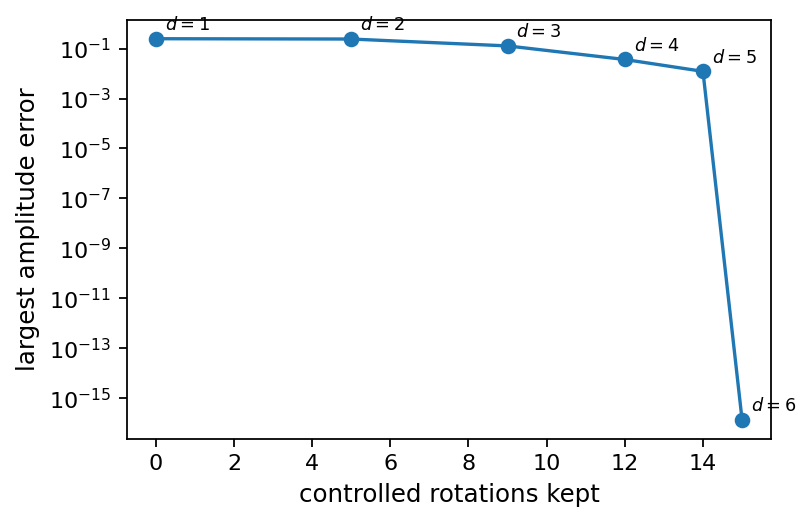

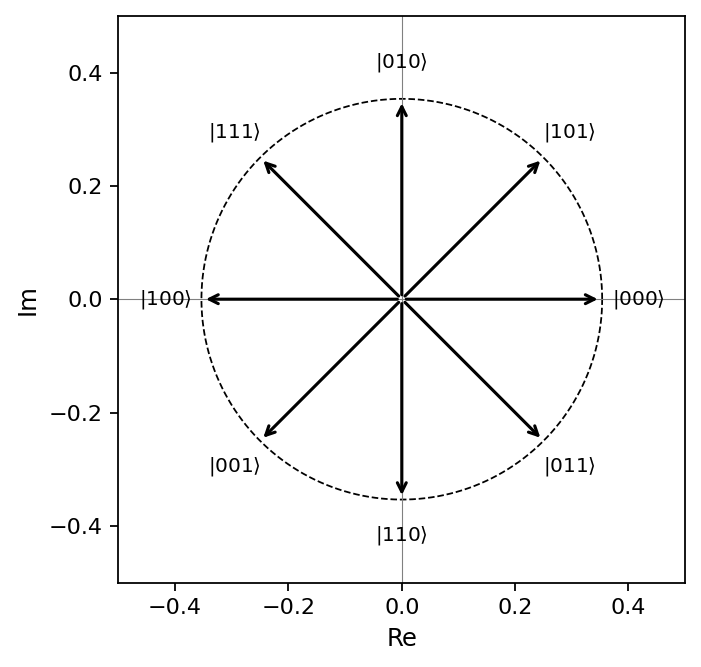

In [5]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter6/qft.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter6').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== Exact case: U = diag(1, e^{2 pi i phi}) with phi = 5/8 = 0.101, eigenstate |1>, m = 3
  outcome |101> with probability 1.000000, estimate 0.625000
  circuit and spectral implementations agree on a random two-qubit Hamiltonian

=== Inexact case: phi = 0.3 = 0.0100110011..., increasing the register (Table 6.inexact)
  m      outcome  probability   estimate     error  two best
  3        |010>       0.5775   0.250000   5.0e-02     0.837
  4       |0101>       0.8756   0.312500   1.3e-02     0.931
  6     |010011>       0.8752   0.296875   3.1e-03     0.930
  8   |01001101>       0.8751   0.300781   7.8e-04     0.930
  every distribution equals the Dirichlet kernel of Eq. (6.dirichlet)



=== The worst case over a whole grid interval, m = 6
  smallest modal probability 0.4054 at phi = 0.16406 (midpoint 10.5/64 = 0.16406); bound 4/pi^2 = 0.4053
  smallest probability of landing within one grid step: 0.8107 >= 8/pi^2 = 0.8106

=== Iterative phase estimation with one control qubit
  phi = 0.6250, m = 3: bits 101, estimate 0.625000, error 0.0e+00
  phi = 0.3000, m = 8: bits 01001101, estimate 0.300781, error 7.8e-04

phase-estimation checks passed


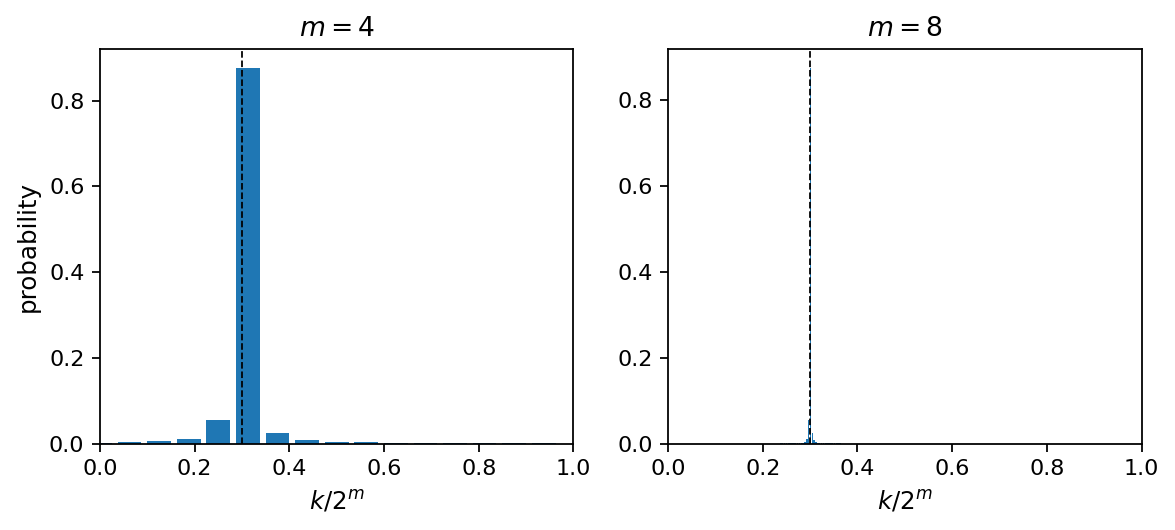

In [6]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter6/phase_estimation.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter6').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== One qubit: the tapered two-level pairing Hamiltonian H = I/2 + Z - X/2 (Eq. 4.tapered)
  spectrum [-0.618034  1.618034], Lambda = 1.5 after removing the identity, t = 1.8850
  m      outcome          E    |E-E0|    prob
  3          011  -0.750000   1.3e-01   0.714
  4         0101  -0.541667   7.6e-02   0.630
  5        01011  -0.645833   2.8e-02   0.787
  6       010101  -0.593750   2.4e-02   0.461
  7      0101011  -0.619792   1.8e-03   0.985
  8     01010110  -0.619792   1.8e-03   0.941
 10   0101010111  -0.616536   1.5e-03   0.471
  keeping the identity: t = 1.4137, E_QPE = -0.625000 (exact -0.618034); without the shift the resolution is 0.0087 instead of 0.0065
  the two-qubit form of Eq. (4.jwpairingtwolevels) in the one-pair sector returns the same outcomes and probabilities

=== Two qubits: the two-mode Hamiltonian of Eq. (4.twoqubitH), eps = (1, 2), t = 0.3, U = 0.5
  spectrum [0.       0.916905 2.083095 3.5     ]; the one-particle block holds 0.916905 and 2.083095
  Lamb

  pairing, $L=4$   4          0100    0.277778  3.6e-01  0.733
  pairing, $L=4$   6        001111    0.572917  6.3e-02  0.860
  pairing, $L=4$   8      00111011    0.646701  1.1e-02  0.927
  pairing, $L=4$  10    0011101101    0.628255  7.3e-03  0.581


    Hubbard ring   4          0010   -1.555556  5.5e-01  0.879
    Hubbard ring   6        001001   -2.250000  1.5e-01  0.861
    Hubbard ring   8      00100011   -2.076389  2.6e-02  0.926
    Hubbard ring  10    0010001101   -2.119792  1.7e-02  0.585


 Heisenberg ring   4          0101   -2.083333  8.3e-02  0.876
 Heisenberg ring   6        010011   -1.979167  2.1e-02  0.875
 Heisenberg ring   8      01001101   -2.005208  5.2e-03  0.875
 Heisenberg ring  10    0100110011   -1.998698  1.3e-03  0.875



=== What a tighter bound on the spectrum buys: the Hubbard ring with m = 10
                 Pauli 1-norm, t = 0.9 pi / Lambda: t = 0.1414, grid step 0.0434, E_QPE = -2.119792, error 1.7e-02, prob 0.585


...

    1  16  -2.005208  5.2e-03  0.864     3.13e-02           384
    1  32  -2.005208  5.2e-03  0.872     1.56e-02           768
    2   1  -1.979167  2.1e-02  0.936     8.73e-02            46
    2   2  -2.005208  5.2e-03  0.530     2.29e-02            92
    2   4  -2.005208  5.2e-03  0.803     5.79e-03           184


    2   8  -2.005208  5.2e-03  0.858     1.45e-03           368
    2  16  -2.005208  5.2e-03  0.871     3.63e-04           736
    2  32  -2.005208  5.2e-03  0.874     9.08e-05          1472



=== Overlaps of simple trial states with the exact ground states (Table 6.overlaps)
           model  trial state  |c_0|^2 1/|c_0|^2  P(E_0 bits), m=8
   Lipkin, $N=4$         0000   0.9358       1.1            0.8973
  pairing, $L=4$         1100   0.8676       1.2            0.8044
    Hubbard ring     10100101   0.2410       4.1            0.2368
 Heisenberg ring         0101   0.3333       3.0            0.2917

=== The Lipkin model at chi = 2 (eps = 1, V = -2/3, W = 0): reference, mean field and exact (Fig. 6.spectroscopy)
  mean-field energy -2.500000 (Table 4.lipkinmf: -2.500000), exact -3.055050, J = 2 eigenvalues [-3.05505  -2.236068  0.        2.236068  3.05505 ]


      reference $|0000\rangle$: |c_j|^2 over the J=2 levels [0.6845 0.     0.2857 0.     0.0298]; histogram weights [0.6118 0.0007 0.2858 0.0001 0.0267]; fidelity of the collapsed register with the ground state after reading the E_0 bits: 1.0000
    mean field, $\alpha=\pi/3$: |c_j|^2 over the J=2 levels [0.5208 0.444  0.0011 0.0247 0.0093]; histogram weights [0.4655 0.4419 0.0011 0.0246 0.0084]; fidelity of the collapsed register with the ground state after reading the E_0 bits: 1.0000
            exact ground state: |c_j|^2 over the J=2 levels [1. 0. 0. 0. 0.]; histogram weights [0.8938 0.001  0.0001 0.     0.    ]; fidelity of the collapsed register with the ground state after reading the E_0 bits: 1.0000



model phase-estimation checks passed


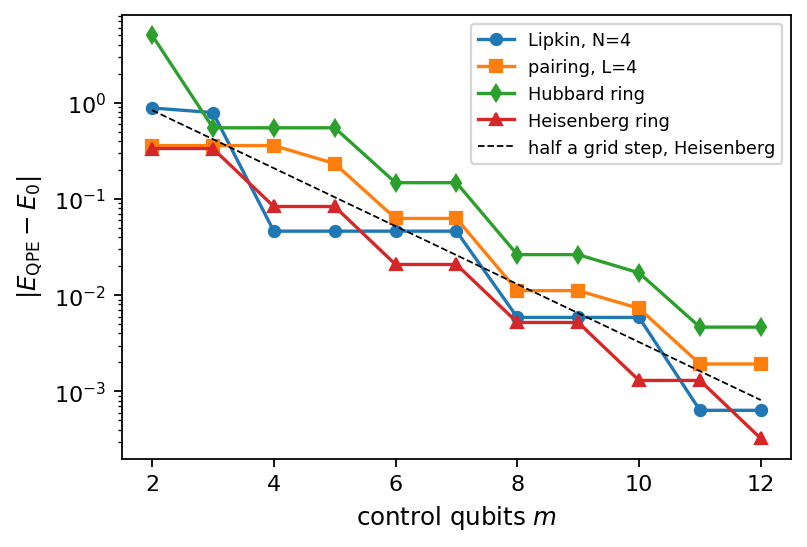

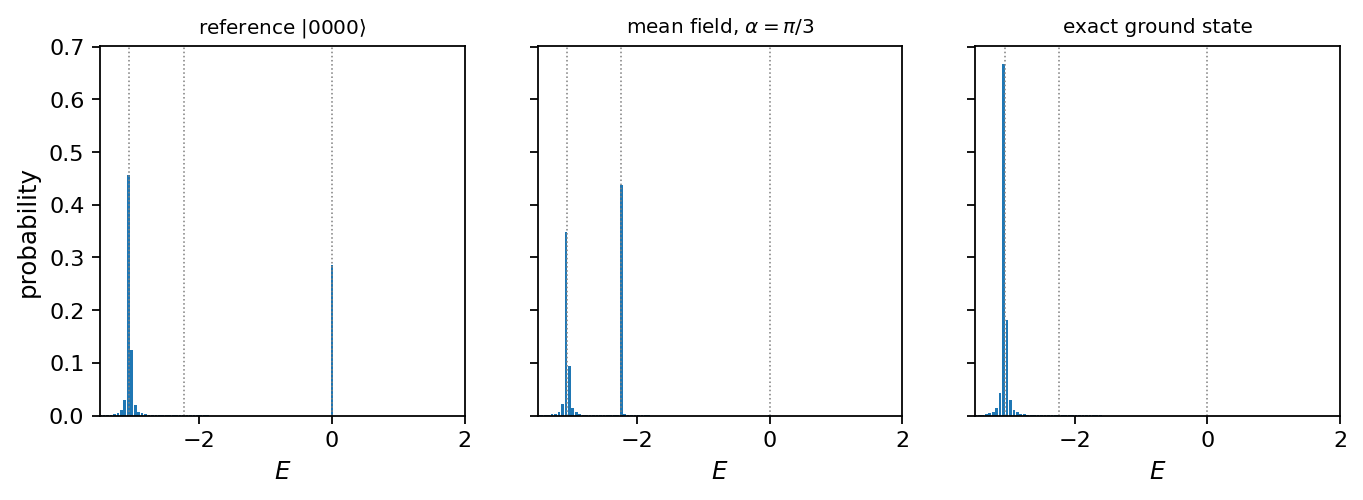

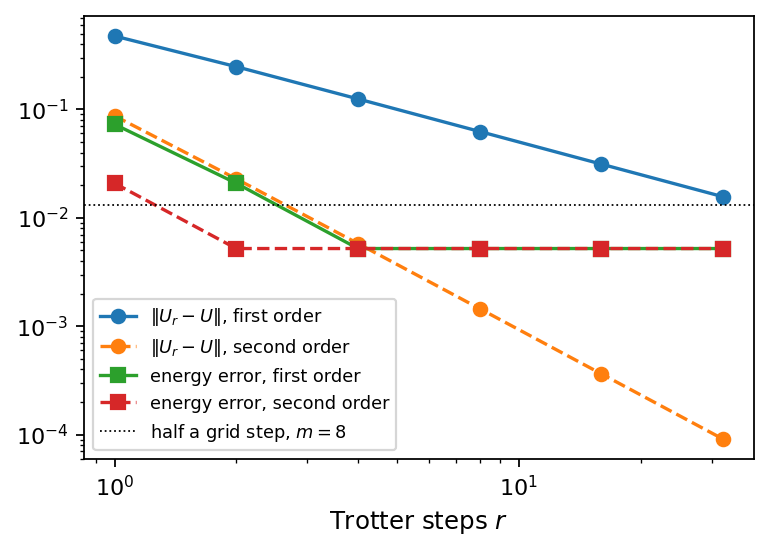

In [7]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter6/qpe_models.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter6').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== A = [[1.5, 0.5], [0.5, 1.5]], b = (1, 0): eigenvalues 1 and 2, t = pi/4, m = 3 (Eq. 6.hhlexample)
  clock distribution after phase estimation: [0.  0.5 0.5 0.  0.  0.  0.  0. ]
    (lambda = 1 -> phi = 1/8 -> |001>, lambda = 2 -> phi = 2/8 -> |010>, each with weight |beta_j|^2 = 1/2)
  success probability 0.625000 (C^2 sum beta_j^2 / lambda_j^2 = 0.625000)
  clock returned to |000>: 1.000000; output state [ 0.948683+0.j -0.316228+0.j]; exact [ 0.948683+0.j -0.316228+0.j]; fidelity 1.0000000000
  classical solution recovered with its scale: [ 0.75 -0.25], exact [ 0.75 -0.25]
  b = |u_max>: success probability 1/kappa^2 for kappa = 2, 5, 10

=== The same system with a generic t = 0.9 pi / 2: the clock no longer represents the eigenvalues exactly (Table 6.hhlclock)
  m       C   window  success  clock reset  1 - fidelity           x (scaled)
  3  0.9000  uniform   0.4081     0.636700      3.30e-01    [ 0.4225 -0.5704]
  4  0.9000  uniform   0.3134     0.641474      4.14e-02    [ 0.617

 10    0.8102   1.000000             1.41e-05          3.25e-03



=== The resolvent (z - H)^{-1} of the two-level pairing Hamiltonian, b = |10> (Fig. 6.hhlresolvent)
  eigenvalues [-0.618034  0.        1.        1.618034], |beta_j|^2 = [0.947214 0.       0.       0.052786]


  m = 6: largest relative error at least 0.3 away from every pole 5.51e-01; success probability at z = 2: 0.0585, at z = -1: 0.7572


  m = 9: largest relative error at least 0.3 away from every pole 2.70e-04; success probability at z = 2: 0.0591, at z = -1: 0.7686
     z   exact G   HHL m=6   HHL m=9  success m=9
 -1.50   -1.0909   -1.0454   -1.0909       0.7708
 -0.25    2.5455    2.5642    2.5458       0.3549
  0.50    0.8000    0.7994    0.8000       0.1620
  2.50    0.3636    0.3609    0.3636       0.1041



HHL checks passed


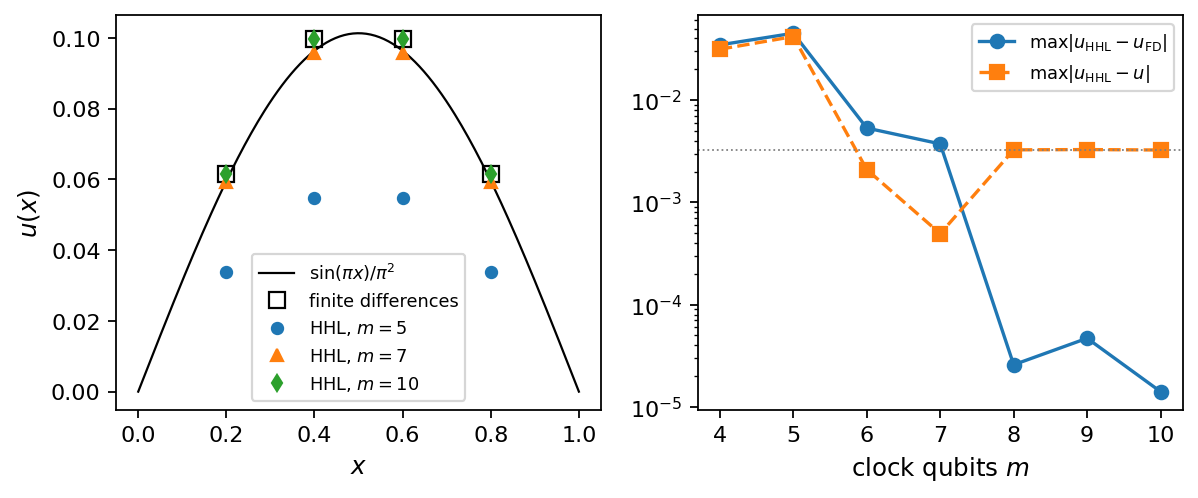

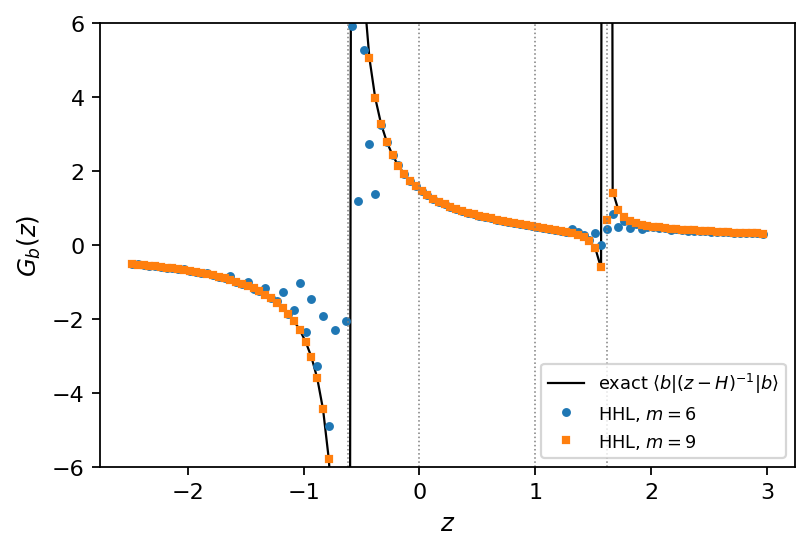

In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter6/hhl.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter6').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
